In [ ]:
!pip install -q datasets pandas numpy scikit-learn matplotlib pillow

In [ ]:
!git clone https://github.com/anvisingla09/UCS532-CV-PROJECT.git

Cloning into 'UCS532-CV-PROJECT'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.


In [ ]:
%cd UCS532-CV-PROJECT

/content/UCS532-CV-PROJECT


In [ ]:
import os

folders = [
    "src",
    "configs",
    "data",
    "results/tables",
    "results/figures",
    "results/logs",
    "report"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder)

Project folders created successfully!
src
configs
data
results/tables
results/figures
results/logs
report


In [ ]:
%%writefile src/load_data.py

import random
import numpy as np
import pandas as pd
from datasets import load_dataset

SEED = 42

def load_bodhisetu():

    random.seed(SEED)
    np.random.seed(SEED)

    print("Loading Bodhisetu enriched dataset...")

    dataset = load_dataset(
        "51Hypers/Bodhisetu",
        "enriched",
        split="train"
    )

    df = dataset.to_pandas()

    print("Dataset loaded successfully!")
    print("Total records:", len(df))

    print("\nMedia distribution:")
    print(df["media_type"].value_counts())

    images_df = df[
        df["media_type"].astype(str).str.upper() == "IMAGE"
    ].copy()

    print("\nTotal image records:", len(images_df))

    return df, images_df


if __name__ == "__main__":

    df, images_df = load_bodhisetu()

    images_df.to_csv(
        "data/dataset_manifest.csv",
        index=False
    )

    print("\nImage manifest saved successfully!")

Writing src/load_data.py


In [ ]:
!python src/load_data.py

Loading Bodhisetu enriched dataset...
Dataset loaded successfully!
Total records: 5753

Media distribution:
media_type
IMAGE    4461
VIDEO    1292
Name: count, dtype: int64

Total image records: 4461

Image manifest saved successfully!


In [ ]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import os
import random

# Fix random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Loading Bodhisetu enriched dataset...")

ds = load_dataset(
    "51Hypers/Bodhisetu",
    "enriched",
    split="train"
)

print("Dataset loaded successfully!")
print(ds)

Loading Bodhisetu enriched dataset...


README.md:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

enriched/data.parquet: reconstructing file:   0%|          |  0.00B / 1.59MB            

enriched/data.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset loaded successfully!
Dataset({
    features: ['entity_uid', 'name', 'language', 'taluk', 'state', 'domain', 'subdomain', 'location_text', 'gps_lat', 'gps_lng', 'keywords_tags', 'significance_status', 'frequency_seasonality', 'time_period_era', 'colloquial_name', 'resource_id', 'media_path', 'media_type', 'description', 'transcript', 'transcript_language'],
    num_rows: 5753
})


In [ ]:
df = ds.to_pandas()

print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nMedia type distribution:")
print(df["media_type"].value_counts())

print("\nHeritage domains:")
print(df["domain"].value_counts())

print("\nFirst five records:")
display(df.head())

Dataset shape: (5753, 21)

All columns:
['entity_uid', 'name', 'language', 'taluk', 'state', 'domain', 'subdomain', 'location_text', 'gps_lat', 'gps_lng', 'keywords_tags', 'significance_status', 'frequency_seasonality', 'time_period_era', 'colloquial_name', 'resource_id', 'media_path', 'media_type', 'description', 'transcript', 'transcript_language']

Media type distribution:
media_type
IMAGE    4461
VIDEO    1292
Name: count, dtype: int64

Heritage domains:
domain
Buildings                  717
Livelihood                 618
Religion                   595
Seasonal & Agricultural    511
Food                       503
Natural Environment        497
History                    446
Transportation             361
Art                        314
Festivals                  303
Technology                 223
Daily Life                 216
Apparel & Jewellery        206
Traditions & Customs       119
Governance                  93
People & Personalities      31
Name: count, dtype: int64

First f

,entity_uid,name,language,taluk,state,domain,subdomain,location_text,gps_lat,gps_lng,...,significance_status,frequency_seasonality,time_period_era,colloquial_name,resource_id,media_path,media_type,description,transcript,transcript_language
0,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Harvesting,"Gorubathan, Mal Forest, West Bengal 735231, India",26.954266,88.730629,...,REGIONAL_SIGNIFICANCE,SEASONAL,COLONIAL,"Cinchona Kheti, Sikkona, Quinine Bagan",NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005_IMG_R020,blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...,IMAGE,"A small, grey shed with a metal roof is positi...",None,None
1,d8c3ebbd3d11f572,Kachiya (Puchi Ferrule),NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Farm Equipment/Agricultural Tools,"CHAMLING NIWAS, SOMBARAY BAZAR, Gorubathan, We...",26.963405,88.627095,...,LOCAL_SIGNIFICANCE,DAILY,COLONIAL,"Hasiya, Sada Kachiya, Dante Kachiya",NEP_GORUBATHAN_AGRI_FARM_EQ_E00011_IMG_R003,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...,IMAGE,A close-up view shows a hand holding the woode...,None,None
2,1832da0c8fdc5403,Tea Plucking in Gorubathan,NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Harvesting,"Gorubathan, North Bengal",26.953147,88.700943,...,COMMONPLACE,SEASONAL,CONTEMPORARY,Doh-Sokha'r Chai Tola,NEP_GORUBATHAN_AGRI_HARVEST_E00003_IMG_R005,blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST...,IMAGE,A woman in a blue shirt and red head covering ...,None,None
3,09da45c62ff0dcad,Janto,NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Farm Equipment/Agricultural Tools,Gorubathan,26.987195,88.692481,...,LOCAL_SIGNIFICANCE,DAILY,TIMELESS_UNKNOWN,"Jato, Atta Chakki, Chakki, Jata, Hāto, Mānī",NEP_GORUBATHAN_AGRI_FARM_EQ_E00005_IMG_R008,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...,IMAGE,The Janto is a traditional rotary hand-quern u...,None,None
4,92f7cd183235b909,Alaichi Kheti (Gorubathan),NEP,Gorubathan,West Bengal,Seasonal & Agricultural,Harvesting,"CHAMLING NIWAS, SOMBARAY BAZAR, Gorubathan, We...",26.954270,88.730637,...,REGIONAL_SIGNIFICANCE,SEASONAL,CONTEMPORARY,"Black Gold, Kalo Sun, Badi Elachi",NEP_GORUBATHAN_AGRI_CROP_E00020_IMG_R015,blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...,IMAGE,"A close-up, low-angle view of large cardamom p...",None,None


In [ ]:
images_df = df[
    df["media_type"].astype(str).str.upper() == "IMAGE"
].copy()

images_df = images_df.reset_index(drop=True)

print("Total image records:", len(images_df))

display(
    images_df[
        [
            "entity_uid",
            "name",
            "domain",
            "state",
            "description",
            "media_path"
        ]
    ].head(10)
)

Total image records: 4461


,entity_uid,name,domain,state,description,media_path
0,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,"A small, grey shed with a metal roof is positi...",blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
1,d8c3ebbd3d11f572,Kachiya (Puchi Ferrule),Seasonal & Agricultural,West Bengal,A close-up view shows a hand holding the woode...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
2,1832da0c8fdc5403,Tea Plucking in Gorubathan,Seasonal & Agricultural,West Bengal,A woman in a blue shirt and red head covering ...,blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST...
3,09da45c62ff0dcad,Janto,Seasonal & Agricultural,West Bengal,The Janto is a traditional rotary hand-quern u...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
4,92f7cd183235b909,Alaichi Kheti (Gorubathan),Seasonal & Agricultural,West Bengal,"A close-up, low-angle view of large cardamom p...",blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...
5,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,"A wide, open field of harvested medicinal crop...",blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
6,095946b351dd22fd,Bari Elaichi Jhaad (Gorubathan),Seasonal & Agricultural,West Bengal,A wide-angle view of the hilly plantation land...,blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...
7,cd6e0b32fa511c68,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,A view of the plantation grounds showing the w...,blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
8,4839015096526f5a,Large Cardamom Plantation under Alder Shade,Seasonal & Agricultural,West Bengal,A view of a Large Cardamom (Amomum subulatum) ...,blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...
9,28bad5141d39365c,Bamboo Shoot Harvesting in Gorubathan,Seasonal & Agricultural,West Bengal,A close-up view of a freshly harvested bamboo ...,blobs/images/final/NEP_GORUBATHAN_AGRI_VEG_E00...


In [ ]:
os.makedirs("data", exist_ok=True)

manifest_columns = [
    "entity_uid",
    "name",
    "language",
    "taluk",
    "state",
    "domain",
    "subdomain",
    "description",
    "keywords_tags",
    "media_path",
    "media_type"
]

manifest = images_df[manifest_columns].copy()

manifest.to_csv(
    "data/dataset_manifest.csv",
    index=False
)

print("Manifest saved successfully!")
print("Manifest shape:", manifest.shape)

Manifest saved successfully!
Manifest shape: (4461, 11)


In [ ]:
print("Total dataset records:", len(df))
print("Total image records:", len(images_df))

print("\nImage columns:")
print(images_df.columns.tolist())

print("\nSample image records:")
display(
    images_df[
        ["name", "domain", "state", "description", "media_path"]
    ].head(5)
)

Total dataset records: 5753
Total image records: 4461

Image columns:
['entity_uid', 'name', 'language', 'taluk', 'state', 'domain', 'subdomain', 'location_text', 'gps_lat', 'gps_lng', 'keywords_tags', 'significance_status', 'frequency_seasonality', 'time_period_era', 'colloquial_name', 'resource_id', 'media_path', 'media_type', 'description', 'transcript', 'transcript_language']

Sample image records:


,name,domain,state,description,media_path
0,Gorubathan Cinchona Bagan,Seasonal & Agricultural,West Bengal,"A small, grey shed with a metal roof is positi...",blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_...
1,Kachiya (Puchi Ferrule),Seasonal & Agricultural,West Bengal,A close-up view shows a hand holding the woode...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
2,Tea Plucking in Gorubathan,Seasonal & Agricultural,West Bengal,A woman in a blue shirt and red head covering ...,blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST...
3,Janto,Seasonal & Agricultural,West Bengal,The Janto is a traditional rotary hand-quern u...,blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ...
4,Alaichi Kheti (Gorubathan),Seasonal & Agricultural,West Bengal,"A close-up, low-angle view of large cardamom p...",blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E0...


In [ ]:
import os

print(os.path.exists("data/dataset_manifest.csv"))

True


In [ ]:
from huggingface_hub import HfApi

api = HfApi()
repo_id = "51Hypers/Bodhisetu"

# Get a few image paths from our manifest
sample_paths = images_df["media_path"].dropna().head(5).tolist()

print("Sample image paths:")
for path in sample_paths:
    print(path)

# Check whether these files exist in the dataset repository
for path in sample_paths:
    try:
        info = api.get_paths_info(
            repo_id=repo_id,
            paths=[path],
            repo_type="dataset"
        )
        if info:
            print("FOUND:", path, "| Size:", info[0].size, "bytes")
        else:
            print("NOT FOUND:", path)
    except Exception as e:
        print("CHECK FAILED:", path, "|", str(e)[:200])

Sample image paths:
blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005_IMG_R020.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011_IMG_R003.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST_E00003/NEP_GORUBATHAN_AGRI_HARVEST_E00003_IMG_R005.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00005/NEP_GORUBATHAN_AGRI_FARM_EQ_E00005_IMG_R008.jpg
blobs/images/final/NEP_GORUBATHAN_AGRI_CROP_E00020/NEP_GORUBATHAN_AGRI_CROP_E00020_IMG_R015.jpg
FOUND: blobs/images/final/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005/NEP_GORUBATHAN_NAT_ENV_MED_PLT_E00005_IMG_R020.jpg | Size: 3120522 bytes
FOUND: blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011/NEP_GORUBATHAN_AGRI_FARM_EQ_E00011_IMG_R003.jpg | Size: 1597179 bytes
FOUND: blobs/images/final/NEP_GORUBATHAN_AGRI_HARVEST_E00003/NEP_GORUBATHAN_AGRI_HARVEST_E00003_IMG_R005.jpg | Size: 1162517 bytes
FOUND: blobs/images/final/NEP_GORUBATHAN_AGRI_FARM_EQ_E00005/NEP_GORUBA

In [ ]:
import os
import shutil
import pandas as pd
from huggingface_hub import hf_hub_download

# Select 50 images from each category
selected_domains = ["Buildings", "Religion", "History", "Art"]

subset = images_df[
    images_df["domain"].isin(selected_domains)
].groupby("domain", group_keys=False).apply(
    lambda x: x.drop_duplicates("entity_uid").sample(
        n=min(50, x["entity_uid"].nunique()),
        random_state=42
    )
).reset_index(drop=True)

print("Selected images:", len(subset))
print("\nCategory distribution:")
print(subset["domain"].value_counts())

# Create image folder
os.makedirs("data/images", exist_ok=True)

# Download selected images
downloaded = []

for i, row in subset.iterrows():
    try:
        image_path = hf_hub_download(
            repo_id="51Hypers/Bodhisetu",
            filename=row["media_path"],
            repo_type="dataset"
        )

        destination = f"data/images/{i}.jpg"
        shutil.copy2(image_path, destination)

        downloaded.append({
            "image_id": i,
            "local_path": destination,
            "name": row["name"],
            "domain": row["domain"],
            "state": row["state"],
            "description": row["description"],
            "entity_uid": row["entity_uid"]
        })

        if len(downloaded) % 10 == 0:
            print("Downloaded:", len(downloaded))

    except Exception as e:
        print("Failed:", row["media_path"], str(e))

# Save metadata for downloaded images only
subset_manifest = pd.DataFrame(downloaded)
subset_manifest.to_csv("data/subset_manifest.csv", index=False)

print("\nDownload complete!")
print("Successfully downloaded:", len(downloaded))
print("Manifest saved: data/subset_manifest.csv")

/tmp/ipykernel_760/1739306893.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ].groupby("domain", group_keys=False).apply(


Selected images: 200

Category distribution:
domain
Art          50
Buildings    50
History      50
Religion     50
Name: count, dtype: int64


blobs/images/final/ASM_TAL1_ART_MUS_INST(…): reconstructing file:   0%|          |  0.00B / 2.60MB            

blobs/images/final/ASM_TAL1_ART_MUS_INST(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): reconstructing file:   0%|          |  0.00B / 1.26MB            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): downloading bytes:           |  0.00B            

... (412 outputs left out)

blobs/images/final/KAN_TAL1_REL_WORSHIP_(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): reconstructing file:   0%|          |  0.00B / 2.84MB            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): downloading bytes:           |  0.00B            

Downloaded: 200

Download complete!
Successfully downloaded: 200
Manifest saved: data/subset_manifest.csv


Total images in manifest: 200
Valid images: 200
Invalid images: 0


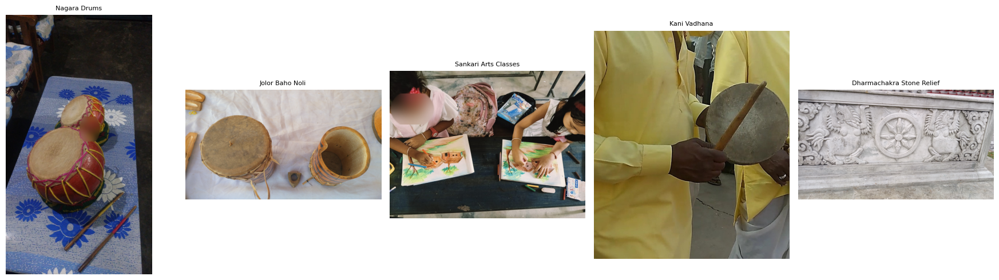

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

manifest = pd.read_csv("data/subset_manifest.csv")

print("Total images in manifest:", len(manifest))

valid_images = []

for path in manifest["local_path"]:
    try:
        img = Image.open(path)
        img.verify()
        valid_images.append(path)
    except Exception as e:
        print("Invalid image:", path, e)

print("Valid images:", len(valid_images))
print("Invalid images:", len(manifest) - len(valid_images))

# Display first 5 images
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (_, row) in zip(axes, manifest.head(5).iterrows()):
    img = Image.open(row["local_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(row["name"][:25], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q transformers torch torchvision

In [ ]:
import torch
from transformers import CLIPProcessor, CLIPModel

MODEL_NAME = "openai/clip-vit-base-patch32"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

model = CLIPModel.from_pretrained(MODEL_NAME)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)

model = model.to(device)
model.eval()

print("CLIP model loaded successfully!")

Using device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully!


In [ ]:

import torch
import numpy as np
import pandas as pd
from PIL import Image
import os

# Load our 200-image manifest
manifest = pd.read_csv("data/subset_manifest.csv")

all_embeddings = []
batch_size = 16

# Generate embeddings in batches
with torch.no_grad():

    for start in range(0, len(manifest), batch_size):

        batch = manifest.iloc[start:start + batch_size]

        images = [
            Image.open(path).convert("RGB")
            for path in batch["local_path"]
        ]

        inputs = processor(
            images=images,
            return_tensors="pt"
        ).to(device)

        features = model.get_image_features(**inputs)

        # Normalize embeddings for cosine similarity
        features = features / features.norm(
            dim=-1, keepdim=True
        )

        all_embeddings.append(features.cpu().numpy())

        print(
            f"Processed {min(start + batch_size, len(manifest))}"
            f" / {len(manifest)} images"
        )

# Combine all batches
image_embeddings = np.concatenate(all_embeddings, axis=0)

# Save embeddings
os.makedirs("results", exist_ok=True)

np.save("results/image_embeddings.npy", image_embeddings)

print("\nImage embedding generation complete!")
print("Embedding shape:", image_embeddings.shape)
print("Embeddings saved successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'data/subset_manifest.csv'

In [ ]:
import os

print("Current working directory:", os.getcwd())
print("\nFolders in current location:")
print(os.listdir("."))

print("\nSearching for subset_manifest.csv...")

for root, dirs, files in os.walk("/content"):
    if "subset_manifest.csv" in files:
        print("FOUND:", os.path.join(root, "subset_manifest.csv"))


Current working directory: /content

Folders in current location:
['.config', 'sample_data']

Searching for subset_manifest.csv...


In [ ]:
!git clone https://github.com/anvisingla09/UCS532-CV-PROJECT.git
%cd /content/UCS532-CV-PROJECT

Cloning into 'UCS532-CV-PROJECT'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.
/content/UCS532-CV-PROJECT


In [ ]:
import os
print("Current folder:", os.getcwd())
print("Project files:", os.listdir("."))

Current folder: /content/UCS532-CV-PROJECT
Project files: ['README.md', '.gitignore', '.git']


In [ ]:
!git config --global user.name "anvisingla09"
!git config --global user.email "aanvi1_be24@thapar.edu"

In [ ]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
!pwd
!ls -la

/content/UCS532-CV-PROJECT
total 24
drwxr-xr-x 3 root root 4096 Nov 27 10:47 .
drwxr-xr-x 1 root root 4096 Nov 27 10:47 ..
drwxr-xr-x 8 root root 4096 Nov 27 10:50 .git
-rw-r--r-- 1 root root 4698 Nov 27 10:47 .gitignore
-rw-r--r-- 1 root root   38 Nov 27 10:47 README.md


In [ ]:
import os

folders = [
    "src",
    "configs",
    "data/images",
    "results/tables",
    "results/figures",
    "results/logs",
    "report"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("All project folders created!")

All project folders created!


In [ ]:
!ls -R

.:
configs  data  README.md  report  results  src

./configs:

./data:
images

./data/images:

./report:

./results:
figures  logs  tables

./results/figures:

./results/logs:

./results/tables:

./src:


In [ ]:
!git add .
!git commit -m "Create initial project structure"
!git push

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
import os

folders = [
    "src", "configs", "data/images",
    "results/tables", "results/figures",
    "results/logs", "report"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)
    with open(os.path.join(folder, ".gitkeep"), "w") as f:
        pass

print("Project folders prepared!")

Project folders prepared!


In [ ]:
import getpass
import subprocess

username = input("Enter your GitHub username: ")
token = getpass.getpass("Paste your GitHub token: ")

credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={username}\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

token = None
print("GitHub authentication configured for this Colab session!")

Enter your GitHub username: anvisingla09
Paste your GitHub token: ··········
GitHub authentication configured for this Colab session!


In [ ]:
!git add .
!git commit -m "Create initial project structure"
!git push origin main

[main 2c300c7] Create initial project structure
 7 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 configs/.gitkeep
 create mode 100644 data/images/.gitkeep
 create mode 100644 report/.gitkeep
 create mode 100644 results/figures/.gitkeep
 create mode 100644 results/logs/.gitkeep
 create mode 100644 results/tables/.gitkeep
 create mode 100644 src/.gitkeep
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!git config --global credential.helper store

In [ ]:
import getpass
import subprocess

username = input("GitHub username: ")
token = getpass.getpass("GitHub Personal Access Token: ")

credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={username}\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

token = None
print("Credentials configured!")

GitHub username: anvisingla09
GitHub Personal Access Token: ··········
Credentials configured!


In [ ]:
!git push origin main

To https://github.com/anvisingla09/UCS532-CV-PROJECT.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/anvisingla09/UCS532-CV-PROJECT.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [ ]:
!git pull --rebase origin main

remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 1.12 MiB | 2.52 MiB/s, done.
From https://github.com/anvisingla09/UCS532-CV-PROJECT
 * branch            main       -> FETCH_HEAD
   1385b1e..b459b3c  main       -> origin/main
Successfully rebased and updated refs/heads/main.


In [ ]:
!git push origin main

Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (6/6), 605 bytes | 605.00 KiB/s, done.
Total 6 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/anvisingla09/UCS532-CV-PROJECT.git
   b459b3c..576bca8  main -> main


In [ ]:
%cd /content/UCS532-CV-PROJECT

/content/UCS532-CV-PROJECT


In [ ]:
!pwd

/content/UCS532-CV-PROJECT


In [ ]:

from datasets import load_dataset
import pandas as pd
import numpy as np
import random
import os

# Reproducibility
random.seed(42)
np.random.seed(42)

print("Loading Bodhisetu enriched dataset...")

dataset = load_dataset(
    "51Hypers/Bodhisetu",
    "enriched",
    split="train"
)

df = dataset.to_pandas()

# Select image records
images_df = df[
    df["media_type"].astype(str).str.upper() == "IMAGE"
].copy()

print("\nDataset loaded successfully!")
print("Total records:", len(df))
print("Total image records:", len(images_df))

print("\nImage distribution by domain:")
print(images_df["domain"].value_counts())


Loading Bodhisetu enriched dataset...


README.md:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

enriched/data.parquet: reconstructing file:   0%|          |  0.00B / 1.59MB            

enriched/data.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]


Dataset loaded successfully!
Total records: 5753
Total image records: 4461

Image distribution by domain:
domain
Buildings                  584
Livelihood                 481
Religion                   445
Natural Environment        411
Seasonal & Agricultural    400
Food                       373
History                    341
Transportation             280
Art                        229
Festivals                  208
Technology                 182
Apparel & Jewellery        171
Daily Life                 170
Traditions & Customs        86
Governance                  76
People & Personalities      24
Name: count, dtype: int64


In [ ]:
images_df.to_csv("data/dataset_manifest.csv", index=False)

print("Dataset manifest saved!")
print("File exists:", os.path.exists("data/dataset_manifest.csv"))

Dataset manifest saved!
File exists: True


In [ ]:
%%writefile src/load_data.py
import random
import numpy as np
import pandas as pd
from datasets import load_dataset

SEED = 42

def load_bodhisetu():
    random.seed(SEED)
    np.random.seed(SEED)

    print("Loading Bodhisetu enriched dataset...")

    dataset = load_dataset(
        "51Hypers/Bodhisetu",
        "enriched",
        split="train"
    )

    df = dataset.to_pandas()

    images_df = df[
        df["media_type"].astype(str).str.upper() == "IMAGE"
    ].copy()

    print("Total records:", len(df))
    print("Total images:", len(images_df))

    return df, images_df

if __name__ == "__main__":
    df, images_df = load_bodhisetu()
    images_df.to_csv("data/dataset_manifest.csv", index=False)
    print("Manifest saved!")

Writing src/load_data.py


In [ ]:
!git add src/load_data.py data/dataset_manifest.csv
!git commit -m "Add Bodhisetu dataset loading and image manifest"
!git push origin main

[main 6fae922] Add Bodhisetu dataset loading and image manifest
 2 files changed, 4496 insertions(+)
 create mode 100644 data/dataset_manifest.csv
 create mode 100644 src/load_data.py
To https://github.com/anvisingla09/UCS532-CV-PROJECT.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/anvisingla09/UCS532-CV-PROJECT.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [ ]:
!git pull --rebase origin main

remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 2 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (2/2), 876 bytes | 876.00 KiB/s, done.
From https://github.com/anvisingla09/UCS532-CV-PROJECT
 * branch            main       -> FETCH_HEAD
   576bca8..0e76bde  main       -> origin/main
Successfully rebased and updated refs/heads/main.


In [ ]:
!git push origin main

Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 780.51 KiB | 5.61 MiB/s, done.
Total 6 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/anvisingla09/UCS532-CV-PROJECT.git
   0e76bde..2e67679  main -> main


In [ ]:
selected_domains = ["Buildings", "Religion", "History", "Art"]

subset = (
    images_df[images_df["domain"].isin(selected_domains)]
    .groupby("domain", group_keys=False)
    .apply(
        lambda x: x.drop_duplicates("entity_uid").sample(
            n=min(50, x["entity_uid"].nunique()),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("Selected images:", len(subset))
print("\nImages per category:")
print(subset["domain"].value_counts())

Selected images: 200

Images per category:
domain
Art          50
Buildings    50
History      50
Religion     50
Name: count, dtype: int64


/tmp/ipykernel_382/75853779.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [ ]:
import os
import shutil
import pandas as pd
from huggingface_hub import hf_hub_download

os.makedirs("data/images", exist_ok=True)

downloaded = []

for i, (_, row) in enumerate(subset.iterrows()):
    try:
        image_path = hf_hub_download(
            repo_id="51Hypers/Bodhisetu",
            filename=row["media_path"],
            repo_type="dataset"
        )

        destination = f"data/images/{i}.jpg"
        shutil.copy2(image_path, destination)

        downloaded.append({
            "image_id": i,
            "local_path": destination,
            "name": row["name"],
            "domain": row["domain"],
            "state": row["state"],
            "description": row["description"],
            "entity_uid": row["entity_uid"]
        })

        if len(downloaded) % 25 == 0:
            print("Downloaded:", len(downloaded))

    except Exception as e:
        print("Failed:", row["media_path"], str(e))

subset_manifest = pd.DataFrame(downloaded)
subset_manifest.to_csv("data/subset_manifest.csv", index=False)

print("\nSuccessfully downloaded:", len(downloaded))
print("Manifest saved!")

blobs/images/final/ASM_TAL1_ART_MUS_INST(…): reconstructing file:   0%|          |  0.00B / 2.60MB            

blobs/images/final/ASM_TAL1_ART_MUS_INST(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): reconstructing file:   0%|          |  0.00B / 1.26MB            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_TAL4_ART_TEACH_E0(…): reconstructing file:   0%|          |  0.00B /  311kB            

blobs/images/final/ASM_TAL4_ART_TEACH_E0(…): downloading bytes:           |  0.00B            

... (398 outputs left out)

blobs/images/final/KAN_TAL1_REL_WORSHIP_(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): reconstructing file:   0%|          |  0.00B / 2.84MB            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): downloading bytes:           |  0.00B            

Downloaded: 200

Successfully downloaded: 200
Manifest saved!


In [ ]:
from PIL import Image
import os

valid_images = 0
invalid_images = []

for i in range(200):
    path = f"data/images/{i}.jpg"

    try:
        img = Image.open(path)
        img.verify()
        valid_images += 1
    except Exception as e:
        invalid_images.append((path, str(e)))

print("Valid images:", valid_images)
print("Invalid images:", len(invalid_images))
print("Total image files:", len(os.listdir("data/images")))

Valid images: 200
Invalid images: 0
Total image files: 201


In [ ]:
!pip install -q transformers torch torchvision

import torch
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device)

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

model.eval()

print("CLIP model loaded successfully!")

Using device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully!


In [ ]:
import torch
import clip
import numpy as np
import random
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


In [ ]:
model, preprocess = clip.load("ViT-B/32", device=device)

model.eval()

print("CLIP loaded successfully")

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


CLIP loaded successfully


In [ ]:
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

image_embeddings = []

for i in tqdm(range(len(subset_manifest))):
    image_path = subset_manifest.iloc[i]["local_path"]

    image = Image.open(image_path).convert("RGB")

    inputs = processor(
        images=image,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        features = model.get_image_features(**inputs)

        # Normalize embeddings for cosine similarity
        features = features / features.norm(
            dim=-1, keepdim=True
        )

    image_embeddings.append(features.cpu().numpy()[0])

image_embeddings = np.array(image_embeddings)

print("Embedding shape:", image_embeddings.shape)
print("Image embeddings generated successfully!")

  0%|          | 0/200 [00:00<?, ?it/s]

AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'

In [ ]:
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

image_embeddings = []

for i in tqdm(range(len(subset_manifest))):

    image_path = subset_manifest.iloc[i]["local_path"]
    image = Image.open(image_path).convert("RGB")

    inputs = processor(
        images=image,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model.get_image_features(**inputs)

        # Handle different Transformers output formats
        if hasattr(outputs, "pooler_output"):
            features = outputs.pooler_output
        elif hasattr(outputs, "image_embeds"):
            features = outputs.image_embeds
        else:
            features = outputs

        # Normalize embeddings
        features = features / features.norm(
            p=2, dim=-1, keepdim=True
        )

    image_embeddings.append(features.cpu().numpy()[0])

image_embeddings = np.array(image_embeddings)

print("Embedding shape:", image_embeddings.shape)
print("Image embeddings generated successfully!")

  0%|          | 0/200 [00:00<?, ?it/s]

Embedding shape: (200, 512)
Image embeddings generated successfully!


In [ ]:
import torch
import numpy as np

def search_images(query, top_k=5):

    # Tokenize text
    inputs = processor(
        text=[query],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    # Generate text embeddings only
    with torch.no_grad():

        text_outputs = model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        pooled_output = text_outputs.pooler_output

        text_features = model.text_projection(pooled_output)

        # Normalize
        text_features = text_features / text_features.norm(
            p=2, dim=-1, keepdim=True
        )

    # Calculate cosine similarity
    similarities = (
        text_features.cpu().numpy() @ image_embeddings.T
    )[0]

    # Retrieve top matching images
    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = subset_manifest.iloc[top_indices].copy()
    results["similarity_score"] = similarities[top_indices]

    return results.reset_index(drop=True)

print("Corrected text-to-image retrieval function!")

Corrected text-to-image retrieval function!


In [ ]:
query = "ancient Indian temple"

results = search_images(query, top_k=5)

print("Search query:", query)

display(
    results[["name", "domain", "state", "similarity_score"]]
)

NameError: name 'image_embeddings' is not defined

In [ ]:
import numpy as np
import os

embedding_path = "results/embeddings/image_embeddings.npy"

print("File exists:", os.path.exists(embedding_path))

image_embeddings = np.load(embedding_path)

print("Image embeddings loaded!")
print("Embedding shape:", image_embeddings.shape)

File exists: False


FileNotFoundError: [Errno 2] No such file or directory: 'results/embeddings/image_embeddings.npy'

In [ ]:
import os

print("Current directory:", os.getcwd())

print("\nProject files:")
for folder in ["data/images", "data", "results/embeddings"]:
    print(f"\n{folder}:")
    if os.path.exists(folder):
        print(os.listdir(folder)[:10])
        print("Total files:", len(os.listdir(folder)))
    else:
        print("Folder does not exist")

Current directory: /content

Project files:

data/images:
Folder does not exist

data:
Folder does not exist

results/embeddings:
Folder does not exist


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/UCS532-CV-PROJECT"

os.makedirs(project_path, exist_ok=True)

print("Project folder created!")
print(project_path)

Project folder created!
/content/drive/MyDrive/UCS532-CV-PROJECT


In [ ]:
import os

project_path = "/content/drive/MyDrive/UCS532-CV-PROJECT"

%cd /content/drive/MyDrive

!git clone https://github.com/anvisingla09/UCS532-CV-PROJECT.git UCS532-CV-PROJECT

/content/drive/MyDrive
Cloning into 'UCS532-CV-PROJECT'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 21 (delta 4), reused 12 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 1.88 MiB | 7.06 MiB/s, done.
Resolving deltas: 100% (4/4), done.


In [ ]:
%cd /content/drive/MyDrive/UCS532-CV-PROJECT

!ls

/content/drive/MyDrive/UCS532-CV-PROJECT
configs  data  README.md  report  results  src


In [ ]:
import os

folders = [
    "data/images",
    "results/embeddings",
    "results/tables",
    "results/figures",
    "results/logs"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("All project directories are ready!")


All project directories are ready!


In [ ]:
import pandas as pd
import os

# Load existing dataset manifest
images_df = pd.read_csv("data/dataset_manifest.csv")

print("Total image records:", len(images_df))

# Select the same four categories
selected_domains = ["Buildings", "Religion", "History", "Art"]

subset = (
    images_df[images_df["domain"].isin(selected_domains)]
    .groupby("domain", group_keys=False)
    .apply(
        lambda x: x.drop_duplicates("entity_uid").sample(
            n=50,
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("\nSelected images:", len(subset))
print("\nImages per category:")
print(subset["domain"].value_counts())

# Save selection permanently
subset.to_csv("data/selected_200.csv", index=False)

print("\nSelected image list saved in Google Drive!")

Total image records: 4461

Selected images: 200

Images per category:
domain
Art          50
Buildings    50
History      50
Religion     50
Name: count, dtype: int64

Selected image list saved in Google Drive!


/tmp/ipykernel_635/456912963.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [ ]:
import os
import shutil
import pandas as pd
from huggingface_hub import hf_hub_download

os.makedirs("data/images", exist_ok=True)

downloaded = []
failed = []

for i, (_, row) in enumerate(subset.iterrows()):

    destination = f"data/images/{i}.jpg"

    try:
        image_path = hf_hub_download(
            repo_id="51Hypers/Bodhisetu",
            filename=row["media_path"],
            repo_type="dataset"
        )

        shutil.copy2(image_path, destination)

        downloaded.append({
            "image_id": i,
            "local_path": destination,
            "name": row["name"],
            "domain": row["domain"],
            "state": row["state"],
            "description": row["description"],
            "entity_uid": row["entity_uid"]
        })

        if len(downloaded) % 25 == 0:
            print("Downloaded:", len(downloaded))

    except Exception as e:
        failed.append((i, str(e)))

subset_manifest = pd.DataFrame(downloaded)

subset_manifest.to_csv(
    "data/subset_manifest.csv",
    index=False
)

print("\nSuccessfully downloaded:", len(downloaded))
print("Failed downloads:", len(failed))
print("Manifest saved permanently!")

blobs/images/final/ASM_TAL1_ART_MUS_INST(…): reconstructing file:   0%|          |  0.00B / 2.60MB            

blobs/images/final/ASM_TAL1_ART_MUS_INST(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): reconstructing file:   0%|          |  0.00B / 1.26MB            

blobs/images/final/ASM_TAL4_TECH_PUB_INF(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_TAL4_ART_TEACH_E0(…): reconstructing file:   0%|          |  0.00B /  311kB            

blobs/images/final/ASM_TAL4_ART_TEACH_E0(…): downloading bytes:           |  0.00B            

... (398 outputs left out)

blobs/images/final/KAN_TAL1_REL_WORSHIP_(…): downloading bytes:           |  0.00B            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): reconstructing file:   0%|          |  0.00B / 2.84MB            

blobs/images/final/ASM_GUWAHATI_REL_REL_(…): downloading bytes:           |  0.00B            

Downloaded: 200

Successfully downloaded: 200
Failed downloads: 0
Manifest saved permanently!


In [1]:
!pip install -q transformers torch torchvision

import torch
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device)

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

model.eval()

print("CLIP model loaded successfully!")


Using device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully!


In [2]:
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
import os

image_embeddings = []

for i in tqdm(range(len(subset_manifest))):

    image_path = subset_manifest.iloc[i]["local_path"]
    image = Image.open(image_path).convert("RGB")

    inputs = processor(
        images=image,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():

        outputs = model.get_image_features(**inputs)

        # Extract tensor from Transformers output
        if hasattr(outputs, "pooler_output"):
            features = outputs.pooler_output
        elif hasattr(outputs, "image_embeds"):
            features = outputs.image_embeds
        else:
            features = outputs

        features = features / features.norm(
            p=2, dim=-1, keepdim=True
        )

    image_embeddings.append(features.cpu().numpy()[0])

image_embeddings = np.array(image_embeddings)

print("\nEmbedding shape:", image_embeddings.shape)
print("Image embeddings generated successfully!")

NameError: name 'subset_manifest' is not defined

In [3]:
import pandas as pd
import os

subset_manifest = pd.read_csv("data/subset_manifest.csv")

print("Manifest loaded successfully!")
print("Total images:", len(subset_manifest))
print(subset_manifest.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/subset_manifest.csv'

In [4]:
%cd /content/drive/MyDrive/UCS532-CV-PROJECT

import os

print("Current directory:", os.getcwd())
print("Manifest exists:", os.path.exists("data/subset_manifest.csv"))
print("Images folder exists:", os.path.exists("data/images"))


[Errno 2] No such file or directory: '/content/drive/MyDrive/UCS532-CV-PROJECT'
/content
Current directory: /content
Manifest exists: False
Images folder exists: False


In [5]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

project_path = "/content/drive/MyDrive/UCS532-CV-PROJECT"

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("Project exists:", os.path.exists(project_path))

Drive mounted: True
Project exists: True


In [7]:
%cd /content/drive/MyDrive/UCS532-CV-PROJECT

print("Manifest exists:", os.path.exists("data/subset_manifest.csv"))
print("Images folder exists:", os.path.exists("data/images"))

/content/drive/MyDrive/UCS532-CV-PROJECT
Manifest exists: True
Images folder exists: True


In [8]:
import os
import pandas as pd

subset_manifest = pd.read_csv("data/subset_manifest.csv")

image_files = [
    f for f in os.listdir("data/images")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Manifest records:", len(subset_manifest))
print("Images available:", len(image_files))
print("First 5 images:", image_files[:5])

Manifest records: 200
Images available: 200
First 5 images: ['0.jpg', '1.jpg', '2.jpg', '3.jpg', '4.jpg']


In [9]:
print("CLIP model loaded:", "model" in globals())
print("Device:", device if "device" in globals() else "Not defined")
print("Manifest records:", len(subset_manifest))
print("\nManifest columns:")
print(subset_manifest.columns.tolist())

CLIP model loaded: True
Device: cuda
Manifest records: 200

Manifest columns:
['image_id', 'local_path', 'name', 'domain', 'state', 'description', 'entity_uid']


In [10]:
import torch
import numpy as np
from PIL import Image
import os
from tqdm.auto import tqdm

project_root = "/content/drive/MyDrive/UCS532-CV-PROJECT"

image_embeddings = []

model.eval()

for _, row in tqdm(subset_manifest.iterrows(), total=len(subset_manifest)):

    image_path = os.path.join(project_root, row["local_path"])

    image = Image.open(image_path).convert("RGB")

    inputs = processor(images=image, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        vision_outputs = model.vision_model(
            pixel_values=inputs["pixel_values"]
        )

        pooled = vision_outputs.pooler_output
        features = model.visual_projection(pooled)

        features = features / features.norm(
            p=2, dim=-1, keepdim=True
        )

    image_embeddings.append(features.cpu().numpy()[0])

image_embeddings = np.array(image_embeddings)

print("Embedding shape:", image_embeddings.shape)

  0%|          | 0/200 [00:00<?, ?it/s]

Embedding shape: (200, 512)


In [11]:
import os
import numpy as np

project_root = "/content/drive/MyDrive/UCS532-CV-PROJECT"

embedding_folder = os.path.join(project_root, "results/embeddings")
os.makedirs(embedding_folder, exist_ok=True)

image_embedding_path = os.path.join(
    embedding_folder, "image_embeddings.npy"
)

np.save(image_embedding_path, image_embeddings)

print("Image embeddings saved successfully!")
print("Shape:", image_embeddings.shape)
print("Saved at:", image_embedding_path)

Image embeddings saved successfully!
Shape: (200, 512)
Saved at: /content/drive/MyDrive/UCS532-CV-PROJECT/results/embeddings/image_embeddings.npy


In [12]:
def get_text_embedding(text):
    inputs = processor(
        text=[text],
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        text_outputs = model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        pooled = text_outputs.pooler_output
        features = model.text_projection(pooled)

        features = features / features.norm(
            p=2, dim=-1, keepdim=True
        )

    return features.cpu().numpy()[0]


# Test the function
test_embedding = get_text_embedding("Taj Mahal")

print("Text embedding shape:", test_embedding.shape)
print("Text embedding generated successfully!")

Text embedding shape: (512,)
Text embedding generated successfully!


In [13]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
from PIL import Image
import os

def search_images(query, top_k=5):

    # Convert query into text embedding
    text_embedding = get_text_embedding(query)

    # Calculate similarity with all images
    similarities = cosine_similarity(
        text_embedding.reshape(1, -1),
        image_embeddings
    )[0]

    # Get top matching image indices
    top_indices = np.argsort(similarities)[::-1][:top_k]

    # Prepare results
    results = subset_manifest.iloc[top_indices].copy()
    results["similarity"] = similarities[top_indices]

    return results


print("Image search function created successfully!")

Image search function created successfully!


In [14]:
results = search_images("Ancient Indian temple", top_k=5)

display(
    results[["name", "domain", "state", "similarity"]]
)

,name,domain,state,similarity
166,ಅಗಸ್ತೇಶ್ವರ ಶಿವಾಲಯ (Agastyeshwara Temple),Religion,Karnataka,0.317159
152,Kanakagiri Hill Temple,Religion,Karnataka,0.298913
184,Bali Pita at Perumpannaiyur,Religion,Tamil Nadu,0.294559
118,Nagavalli Veeragallu and Mastigallu,History,Karnataka,0.290509
148,Kanakagiri Jain Heritage Site,History,Karnataka,0.288006


/tmp/ipykernel_488/621948523.py:27: UserWarning: Glyph 3205 (\N{KANNADA LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27: UserWarning: Matplotlib currently does not support Kannada natively.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27: UserWarning: Glyph 3223 (\N{KANNADA LETTER GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27: UserWarning: Glyph 3256 (\N{KANNADA LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27: UserWarning: Glyph 3277 (\N{KANNADA SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27: UserWarning: Glyph 3236 (\N{KANNADA LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27: UserWarning: Glyph 3271 (\N{KANNADA VOWEL SIGN EE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_488/621948523.py:27:

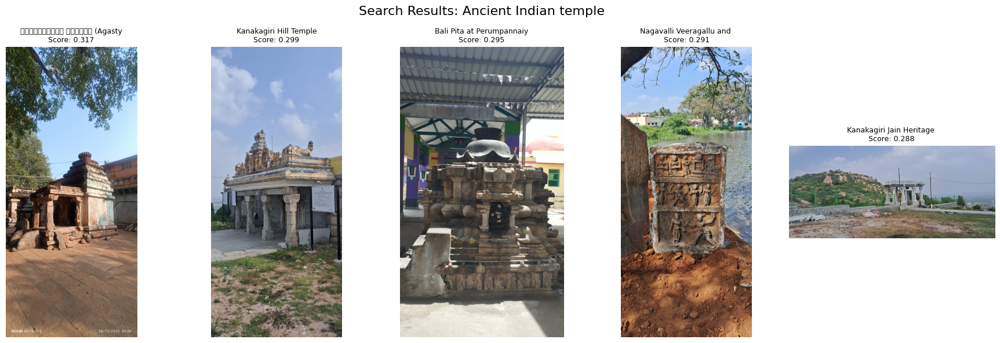

In [15]:
import matplotlib.pyplot as plt
from PIL import Image
import os

query = "Ancient Indian temple"
results = search_images(query, top_k=5)

plt.figure(figsize=(18, 6))

for i, (_, row) in enumerate(results.iterrows()):

    image_path = os.path.join(
        project_root, row["local_path"]
    )

    img = Image.open(image_path).convert("RGB")

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(
        f"{row['name'][:25]}\nScore: {row['similarity']:.3f}",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle(f"Search Results: {query}", fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
test_queries = [
    "Traditional Indian painting",
    "Famous historical buildings in India",
    "Ancient Indian historical monument",
    "Ancient Indian temple"
]

for query in test_queries:

    print("\n" + "="*60)
    print("QUERY:", query)
    print("="*60)

    results = search_images(query, top_k=3)

    display(
        results[["name", "domain", "state", "similarity"]]
    )


QUERY: Traditional Indian painting


,name,domain,state,similarity
138,Chandradhari Mithila Sangrahalay,History,Bihar,0.282365
8,Star Rangoli in Hondarabalu,Art,Karnataka,0.278796
183,Killa Hanumappa Shrine,Religion,Karnataka,0.278027



QUERY: Famous historical buildings in India


,name,domain,state,similarity
166,ಅಗಸ್ತೇಶ್ವರ ಶಿವಾಲಯ (Agastyeshwara Temple),Religion,Karnataka,0.288557
129,Angasi Bagilu,History,Karnataka,0.277075
81,"White Marble Minaret, Ammayiappan Mosque",Buildings,Tamil Nadu,0.274840



QUERY: Ancient Indian historical monument


,name,domain,state,similarity
166,ಅಗಸ್ತೇಶ್ವರ ಶಿವಾಲಯ (Agastyeshwara Temple),Religion,Karnataka,0.310288
148,Kanakagiri Jain Heritage Site,History,Karnataka,0.296008
152,Kanakagiri Hill Temple,Religion,Karnataka,0.295349



QUERY: Ancient Indian temple


,name,domain,state,similarity
166,ಅಗಸ್ತೇಶ್ವರ ಶಿವಾಲಯ (Agastyeshwara Temple),Religion,Karnataka,0.317159
152,Kanakagiri Hill Temple,Religion,Karnataka,0.298913
184,Bali Pita at Perumpannaiyur,Religion,Tamil Nadu,0.294559


In [17]:
import numpy as np
import pandas as pd

evaluation_queries = {
    "Traditional Indian painting": "Art",
    "Famous historical buildings in India": "Buildings",
    "Ancient Indian historical monument": "History",
    "Ancient Indian temple": "Religion"
}

evaluation_results = []

for query, expected_domain in evaluation_queries.items():

    results = search_images(query, top_k=5)

    relevant = (
        results["domain"].values == expected_domain
    )

    hit1 = int(relevant[0])
    hit5 = int(any(relevant))

    relevant_ranks = np.where(relevant)[0] + 1

    if len(relevant_ranks) > 0:
        reciprocal_rank = 1 / relevant_ranks[0]
    else:
        reciprocal_rank = 0

    evaluation_results.append({
        "Query": query,
        "Expected Domain": expected_domain,
        "Hit@1": hit1,
        "Hit@5": hit5,
        "MRR": reciprocal_rank
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

print("\nAVERAGE METRICS")
print("Hit@1:", round(evaluation_df["Hit@1"].mean(), 3))
print("Hit@5:", round(evaluation_df["Hit@5"].mean(), 3))
print("MRR:", round(evaluation_df["MRR"].mean(), 3))

,Query,Expected Domain,Hit@1,Hit@5,MRR
0,Traditional Indian painting,Art,0,1,0.500000
1,Famous historical buildings in India,Buildings,0,1,0.333333
2,Ancient Indian historical monument,History,0,1,0.500000
3,Ancient Indian temple,Religion,1,1,1.000000



AVERAGE METRICS
Hit@1: 0.25
Hit@5: 1.0
MRR: 0.583


In [18]:
import os

project_root = "/content/drive/MyDrive/UCS532-CV-PROJECT"

tables_folder = os.path.join(
    project_root, "results", "tables"
)

os.makedirs(tables_folder, exist_ok=True)

evaluation_path = os.path.join(
    tables_folder, "domain_evaluation.csv"
)

evaluation_df.to_csv(evaluation_path, index=False)

print("Evaluation results saved!")
print(evaluation_path)

display(evaluation_df)

Evaluation results saved!
/content/drive/MyDrive/UCS532-CV-PROJECT/results/tables/domain_evaluation.csv


,Query,Expected Domain,Hit@1,Hit@5,MRR
0,Traditional Indian painting,Art,0,1,0.500000
1,Famous historical buildings in India,Buildings,0,1,0.333333
2,Ancient Indian historical monument,History,0,1,0.500000
3,Ancient Indian temple,Religion,1,1,1.000000


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Combine image names and descriptions
text_corpus = (
    subset_manifest["name"].fillna("") + " " +
    subset_manifest["description"].fillna("") + " " +
    subset_manifest["state"].fillna("")
)

# Create TF-IDF vectors
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

tfidf_matrix = tfidf_vectorizer.fit_transform(text_corpus)

print("TF-IDF baseline created successfully!")
print("Matrix shape:", tfidf_matrix.shape)

TF-IDF baseline created successfully!
Matrix shape: (200, 2917)


In [20]:
def tfidf_search(query, top_k=5):

    # Convert search query into TF-IDF vector
    query_vector = tfidf_vectorizer.transform([query])

    # Calculate similarity with image descriptions
    similarities = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]

    # Find top matching images
    top_indices = np.argsort(similarities)[::-1][:top_k]

    # Prepare results
    results = subset_manifest.iloc[top_indices].copy()
    results["similarity"] = similarities[top_indices]

    return results


print("TF-IDF search function created successfully!")

TF-IDF search function created successfully!


In [21]:
query = "Ancient Indian temple"

tfidf_results = tfidf_search(query, top_k=5)

display(
    tfidf_results[
        ["name", "domain", "state", "similarity"]
    ]
)

,name,domain,state,similarity
102,Ancient Metallic Statue at Thiyaagaraaja Swamy...,History,Tamil Nadu,0.281362
16,Vattezhuthu Script Educational Chart,Art,Tamil Nadu,0.176955
127,Ancient Inscription at Sri Janardana Swamy and...,History,Karnataka,0.148391
24,Kombu,Art,Karnataka,0.147817
198,Ettugatti Basaveshwara Temple,Religion,Karnataka,0.123973


In [22]:
comparison_results = []

for query, expected_domain in evaluation_queries.items():

    # CLIP results
    clip_result = search_images(query, top_k=5)

    clip_relevant = (
        clip_result["domain"].values == expected_domain
    )

    clip_hit1 = int(clip_relevant[0])
    clip_hit5 = int(any(clip_relevant))

    clip_ranks = np.where(clip_relevant)[0] + 1
    clip_mrr = 1 / clip_ranks[0] if len(clip_ranks) else 0

    # TF-IDF results
    tfidf_result = tfidf_search(query, top_k=5)

    tfidf_relevant = (
        tfidf_result["domain"].values == expected_domain
    )

    tfidf_hit1 = int(tfidf_relevant[0])
    tfidf_hit5 = int(any(tfidf_relevant))

    tfidf_ranks = np.where(tfidf_relevant)[0] + 1
    tfidf_mrr = 1 / tfidf_ranks[0] if len(tfidf_ranks) else 0

    comparison_results.append({
        "Query": query,
        "CLIP Hit@1": clip_hit1,
        "TF-IDF Hit@1": tfidf_hit1,
        "CLIP Hit@5": clip_hit5,
        "TF-IDF Hit@5": tfidf_hit5,
        "CLIP MRR": clip_mrr,
        "TF-IDF MRR": tfidf_mrr
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

print("\nAVERAGE PERFORMANCE")

display(
    comparison_df.drop(columns="Query").mean().to_frame("Average")
)

,Query,CLIP Hit@1,TF-IDF Hit@1,CLIP Hit@5,TF-IDF Hit@5,CLIP MRR,TF-IDF MRR
0,Traditional Indian painting,0,1,1,1,0.500000,1.0
1,Famous historical buildings in India,0,1,1,1,0.333333,1.0
2,Ancient Indian historical monument,0,1,1,1,0.500000,1.0
3,Ancient Indian temple,1,0,1,1,1.000000,0.2



AVERAGE PERFORMANCE


,Average
CLIP Hit@1,0.250000
TF-IDF Hit@1,0.750000
CLIP Hit@5,1.000000
TF-IDF Hit@5,1.000000
CLIP MRR,0.583333
TF-IDF MRR,0.800000


In [23]:
def hybrid_search(query, top_k=5, weight=0.5):

    clip_results = search_images(query, top_k=200)
    tfidf_results = tfidf_search(query, top_k=200)

    clip_ranks = {
        idx: rank + 1
        for rank, idx in enumerate(clip_results.index)
    }

    tfidf_ranks = {
        idx: rank + 1
        for rank, idx in enumerate(tfidf_results.index)
    }

    all_indices = set(clip_ranks) | set(tfidf_ranks)

    scores = {}

    for idx in all_indices:

        clip_score = 1 / (60 + clip_ranks[idx]) if idx in clip_ranks else 0
        tfidf_score = 1 / (60 + tfidf_ranks[idx]) if idx in tfidf_ranks else 0

        scores[idx] = (
            weight * clip_score +
            (1 - weight) * tfidf_score
        )

    ranked_indices = sorted(
        scores, key=scores.get, reverse=True
    )[:top_k]

    results = subset_manifest.loc[ranked_indices].copy()
    results["fusion_score"] = [
        scores[idx] for idx in ranked_indices
    ]

    return results


print("Hybrid rank fusion implemented successfully!")

Hybrid rank fusion implemented successfully!


In [24]:
hybrid_evaluation = []

for query, expected_domain in evaluation_queries.items():

    # Get hybrid results
    results = hybrid_search(query, top_k=5, weight=0.5)

    relevant = (
        results["domain"].values == expected_domain
    )

    hit1 = int(relevant[0])
    hit5 = int(any(relevant))

    ranks = np.where(relevant)[0] + 1
    mrr = 1 / ranks[0] if len(ranks) else 0

    hybrid_evaluation.append({
        "Query": query,
        "Hybrid Hit@1": hit1,
        "Hybrid Hit@5": hit5,
        "Hybrid MRR": mrr
    })

hybrid_df = pd.DataFrame(hybrid_evaluation)

display(hybrid_df)

print("\nAVERAGE HYBRID PERFORMANCE")

display(
    hybrid_df.drop(columns="Query").mean().to_frame("Average")
)

,Query,Hybrid Hit@1,Hybrid Hit@5,Hybrid MRR
0,Traditional Indian painting,0,1,0.5
1,Famous historical buildings in India,0,0,0.0
2,Ancient Indian historical monument,1,1,1.0
3,Ancient Indian temple,0,1,0.5



AVERAGE HYBRID PERFORMANCE


,Average
Hybrid Hit@1,0.25
Hybrid Hit@5,0.75
Hybrid MRR,0.50


In [25]:
final_comparison = pd.DataFrame({
    "Method": ["CLIP", "TF-IDF", "Hybrid"],
    "Hit@1": [0.25, 0.75, 0.25],
    "Hit@5": [1.00, 1.00, 0.75],
    "MRR": [0.583333, 0.800000, 0.500000]
})

display(final_comparison)

save_path = os.path.join(
    project_root,
    "results",
    "tables",
    "final_comparison.csv"
)

final_comparison.to_csv(save_path, index=False)

print("Final comparison saved:", save_path)

,Method,Hit@1,Hit@5,MRR
0,CLIP,0.25,1.00,0.583333
1,TF-IDF,0.75,1.00,0.800000
2,Hybrid,0.25,0.75,0.500000


Final comparison saved: /content/drive/MyDrive/UCS532-CV-PROJECT/results/tables/final_comparison.csv


In [26]:
weights = [0.0, 0.25, 0.50, 0.75, 1.0]

weight_results = []

for weight in weights:

    hits = []
    reciprocal_ranks = []

    for query, expected_domain in evaluation_queries.items():

        results = hybrid_search(
            query,
            top_k=5,
            weight=weight
        )

        relevant = (
            results["domain"].values == expected_domain
        )

        hits.append(int(any(relevant)))

        ranks = np.where(relevant)[0] + 1

        reciprocal_ranks.append(
            1 / ranks[0] if len(ranks) else 0
        )

    weight_results.append({
        "CLIP Weight": weight,
        "Hit@5": np.mean(hits),
        "MRR": np.mean(reciprocal_ranks)
    })

weight_df = pd.DataFrame(weight_results)

display(weight_df)

,CLIP Weight,Hit@5,MRR
0,0.00,1.00,0.800000
1,0.25,1.00,0.583333
2,0.50,0.75,0.500000
3,0.75,0.75,0.500000
4,1.00,1.00,0.583333


In [27]:
print(weight_df.to_string(index=False))

 CLIP Weight  Hit@5      MRR
        0.00   1.00 0.800000
        0.25   1.00 0.583333
        0.50   0.75 0.500000
        0.75   0.75 0.500000
        1.00   1.00 0.583333


In [28]:
weight_df.to_csv(
    "results/tables/weight_ablation.csv",
    index=False
)

print("Weight ablation results saved!")

Weight ablation results saved!


In [29]:
print("Available categories:")
print(subset_manifest["domain"].value_counts())

Available categories:
domain
Art          50
Buildings    50
History      50
Religion     50
Name: count, dtype: int64


In [30]:
evaluation_queries = {
    # Art
    "Traditional Indian painting": "Art",
    "Indian sculpture and artwork": "Art",
    "Ancient Indian artistic designs": "Art",
    "Traditional Indian handicrafts": "Art",

    # Buildings
    "Famous Indian architectural structures": "Buildings",
    "Historic Indian forts and palaces": "Buildings",
    "Ancient Indian buildings": "Buildings",
    "Traditional Indian architecture": "Buildings",

    # History
    "Ancient Indian historical monuments": "History",
    "Indian historical inscriptions": "History",
    "Archaeological heritage of India": "History",
    "Ancient Indian historical objects": "History",

    # Religion
    "Ancient Indian temples": "Religion",
    "Hindu religious heritage": "Religion",
    "Buddhist religious monuments": "Religion",
    "Jain religious heritage": "Religion"
}

print("Total evaluation queries:", len(evaluation_queries))

Total evaluation queries: 16


In [31]:
methods = {
    "CLIP": lambda q: search_images(q, top_k=5),
    "TF-IDF": lambda q: tfidf_search(q, top_k=5),
    "Hybrid": lambda q: hybrid_search(q, top_k=5, weight=0.5)
}

query_results = []

for query, expected_domain in evaluation_queries.items():

    for method_name, search_function in methods.items():

        results = search_function(query)

        relevant = (
            results["domain"].values == expected_domain
        )

        ranks = np.where(relevant)[0] + 1

        query_results.append({
            "Query": query,
            "Expected Domain": expected_domain,
            "Method": method_name,
            "Hit@1": int(len(ranks) > 0 and ranks[0] == 1),
            "Hit@5": int(len(ranks) > 0),
            "MRR": 1 / ranks[0] if len(ranks) > 0 else 0
        })

query_results_df = pd.DataFrame(query_results)

summary_df = (
    query_results_df
    .groupby("Method")[["Hit@1", "Hit@5", "MRR"]]
    .mean()
    .reset_index()
)

print("16-query evaluation results:")
display(summary_df)

16-query evaluation results:


,Method,Hit@1,Hit@5,MRR
0,CLIP,0.25,0.9375,0.557292
1,Hybrid,0.50,0.8750,0.632292
2,TF-IDF,0.50,0.8125,0.597917


In [32]:
query_results_df.to_csv(
    "results/tables/query_level_results.csv",
    index=False
)

summary_df.to_csv(
    "results/tables/16_query_comparison.csv",
    index=False
)

print("Both evaluation files saved successfully!")

Both evaluation files saved successfully!


In [33]:
weights = [0.0, 0.25, 0.50, 0.75, 1.0]

weight_results = []

for weight in weights:
    hits1 = []
    hits5 = []
    reciprocal_ranks = []

    for query, expected_domain in evaluation_queries.items():

        results = hybrid_search(
            query,
            top_k=5,
            weight=weight
        )

        relevant = (
            results["domain"].values == expected_domain
        )

        ranks = np.where(relevant)[0] + 1

        hits1.append(int(len(ranks) > 0 and ranks[0] == 1))
        hits5.append(int(len(ranks) > 0))
        reciprocal_ranks.append(
            1 / ranks[0] if len(ranks) > 0 else 0
        )

    weight_results.append({
        "CLIP Weight": weight,
        "Hit@1": np.mean(hits1),
        "Hit@5": np.mean(hits5),
        "MRR": np.mean(reciprocal_ranks)
    })

weight_df = pd.DataFrame(weight_results)

display(weight_df)

,CLIP Weight,Hit@1,Hit@5,MRR
0,0.00,0.500,0.8125,0.597917
1,0.25,0.375,0.7500,0.541667
2,0.50,0.500,0.8750,0.632292
3,0.75,0.500,0.7500,0.609375
4,1.00,0.250,0.9375,0.557292


In [34]:
weight_df.to_csv(
    "results/tables/weight_ablation_16_queries.csv",
    index=False
)

print("16-query weight ablation saved successfully!")

16-query weight ablation saved successfully!


In [35]:
print("Dataset columns:")
print(subset_manifest.columns.tolist())

print("\nSample record:")
display(subset_manifest.iloc[0])

Dataset columns:
['image_id', 'local_path', 'name', 'domain', 'state', 'description', 'entity_uid']

Sample record:


,0
image_id,0
local_path,data/images/0.jpg
name,Nagara Drums
domain,Art
state,Assam
description,The Nagara is a traditional Assamese percussio...
entity_uid,a2e0026937d6b12a


In [ ]:
import os
from PIL import Image
from IPython.display import display

def interactive_search():
    while True:
        query = input("\nEnter your search query (or type 'exit' to stop): ")

        if query.lower() == "exit":
            print("Search demo ended.")
            break

        results = hybrid_search(query, top_k=5, weight=0.50)

        print(f"\nTop 5 results for: {query}")
        print("=" * 60)

        for rank, (idx, row) in enumerate(results.iterrows(), start=1):
            image_path = os.path.join(project_root, row["local_path"])

            print(f"\nResult {rank}")
            print("Name:", row["name"])
            print("Domain:", row["domain"])
            print("State:", row["state"])
            print("Description:", row["description"])

            if os.path.exists(image_path):
                display(Image.open(image_path))
            else:
                print("Image not found:", image_path)

            print("-" * 60)

interactive_search()

In [38]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from PIL import Image
import base64
from io import BytesIO
import html
import os

query_box = widgets.Text(
    placeholder="e.g. Ancient Indian temples",
    description="Search:",
    layout=widgets.Layout(width="70%")
)

search_button = widgets.Button(
    description="Search",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

def show_results(button):
    with output:
        clear_output(wait=True)

        query = query_box.value.strip()

        if not query:
            print("Please enter a search query.")
            return

        results = hybrid_search(query, top_k=5, weight=0.50)

        cards = ""

        for rank, (idx, row) in enumerate(results.iterrows(), start=1):
            image_path = os.path.join(project_root, row["local_path"])

            if os.path.exists(image_path):
                img = Image.open(image_path).convert("RGB")
                img.thumbnail((300, 220))

                buffer = BytesIO()
                img.save(buffer, format="JPEG")
                encoded = base64.b64encode(buffer.getvalue()).decode()

                image_html = f'<img src="data:image/jpeg;base64,{encoded}" style="width:100%;height:200px;object-fit:contain;background:#f3f3f3;border-radius:8px;">'
            else:
                image_html = "<p>Image not found</p>"

            cards += f"""
            <div style="border:1px solid #ddd;border-radius:12px;
                        padding:12px;width:260px;background:white;">
                {image_html}
                <h3>#{rank} - {html.escape(str(row['name']))}</h3>
                <p><b>Category:</b> {html.escape(str(row['domain']))}</p>
                <p><b>State:</b> {html.escape(str(row['state']))}</p>
                <p style="font-size:13px;line-height:1.5;">
                    {html.escape(str(row['description']))}
                </p>
            </div>
            """

        display(HTML(f"""
        <h2>Search Results</h2>
        <p>Query: <b>{html.escape(query)}</b></p>
        <div style="display:flex;flex-wrap:wrap;gap:15px;">
            {cards}
        </div>
        """))

search_button.on_click(show_results)

display(widgets.VBox([
    widgets.HTML("<h2>Indian Heritage Image Retrieval</h2>"),
    query_box,
    search_button,
    output
]))

In [39]:
evaluation_queries_40 = {
    "Traditional Indian painting": "Art",
    "Indian sculpture and artwork": "Art",
    "Ancient Indian artistic designs": "Art",
    "Traditional Indian handicrafts": "Art",
    "Indian musical instruments": "Art",
    "Traditional Indian folk art": "Art",
    "Indian cultural artefacts": "Art",
    "Ancient Indian statues": "Art",
    "Traditional Indian decorative art": "Art",
    "Indian artistic heritage": "Art",

    "Famous Indian architectural structures": "Buildings",
    "Historic Indian forts and palaces": "Buildings",
    "Ancient Indian buildings": "Buildings",
    "Traditional Indian architecture": "Buildings",
    "Historical Indian monuments": "Buildings",
    "Ancient Indian stone structures": "Buildings",
    "Indian heritage architecture": "Buildings",
    "Historic Indian gateways": "Buildings",
    "Traditional Indian houses": "Buildings",
    "Ancient Indian architectural sites": "Buildings",

    "Ancient Indian historical monuments": "History",
    "Indian historical inscriptions": "History",
    "Archaeological heritage of India": "History",
    "Ancient Indian historical objects": "History",
    "Indian archaeological discoveries": "History",
    "Historical sites in India": "History",
    "Ancient Indian stone carvings": "History",
    "Indian historical landmarks": "History",
    "Ancient Indian artefacts": "History",
    "Indian cultural history": "History",

    "Ancient Indian temples": "Religion",
    "Hindu religious heritage": "Religion",
    "Buddhist religious monuments": "Religion",
    "Jain religious heritage": "Religion",
    "Ancient Hindu shrines": "Religion",
    "Buddhist sculptures and sites": "Religion",
    "Indian religious architecture": "Religion",
    "Jain temples and monuments": "Religion",
    "Sacred Indian heritage sites": "Religion",
    "Ancient Indian religious sculptures": "Religion"
}

print("Total evaluation queries:", len(evaluation_queries_40))

print("\nQueries per category:")
print(pd.Series(evaluation_queries_40).value_counts())

Total evaluation queries: 40

Queries per category:
Art          10
Buildings    10
History      10
Religion     10
Name: count, dtype: int64


In [40]:
import pandas as pd
import os

methods = {
    "CLIP": search_images,
    "TF-IDF": tfidf_search,
    "Hybrid": hybrid_search
}

evaluation_results = []

for method_name, search_function in methods.items():

    for query, relevant_domain in evaluation_queries_40.items():

        if method_name == "Hybrid":
            results = search_function(query, top_k=5, weight=0.50)
        else:
            results = search_function(query, top_k=5)

        retrieved_domains = results["domain"].tolist()

        relevant_ranks = [
            rank for rank, domain in enumerate(retrieved_domains, start=1)
            if domain == relevant_domain
        ]

        hit_at_1 = int(
            len(retrieved_domains) > 0 and
            retrieved_domains[0] == relevant_domain
        )

        hit_at_5 = int(len(relevant_ranks) > 0)

        reciprocal_rank = (
            1 / relevant_ranks[0] if relevant_ranks else 0
        )

        evaluation_results.append({
            "Method": method_name,
            "Query": query,
            "Expected Domain": relevant_domain,
            "Hit@1": hit_at_1,
            "Hit@5": hit_at_5,
            "MRR": reciprocal_rank
        })

evaluation_df_40 = pd.DataFrame(evaluation_results)

print("Evaluation completed!")
print("Total evaluations:", len(evaluation_df_40))

display(evaluation_df_40.head(10))

Evaluation completed!
Total evaluations: 120


,Method,Query,Expected Domain,Hit@1,Hit@5,MRR
0,CLIP,Traditional Indian painting,Art,0,1,0.50
1,CLIP,Indian sculpture and artwork,Art,1,1,1.00
2,CLIP,Ancient Indian artistic designs,Art,0,1,0.50
3,CLIP,Traditional Indian handicrafts,Art,0,1,0.50
4,CLIP,Indian musical instruments,Art,1,1,1.00
5,CLIP,Traditional Indian folk art,Art,1,1,1.00
6,CLIP,Indian cultural artefacts,Art,1,1,1.00
7,CLIP,Ancient Indian statues,Art,0,1,0.25
8,CLIP,Traditional Indian decorative art,Art,1,1,1.00
9,CLIP,Indian artistic heritage,Art,0,1,0.50


In [41]:
final_comparison_40 = (
    evaluation_df_40
    .groupby("Method")[["Hit@1", "Hit@5", "MRR"]]
    .mean()
    .reset_index()
)

final_comparison_40 = final_comparison_40.round(4)

print("FINAL COMPARISON — 40 QUERIES")
display(final_comparison_40)

FINAL COMPARISON — 40 QUERIES


,Method,Hit@1,Hit@5,MRR
0,CLIP,0.375,0.900,0.5829
1,Hybrid,0.500,0.825,0.6300
2,TF-IDF,0.500,0.775,0.5983


In [42]:
evaluation_df_40.to_csv(
    os.path.join(project_root, "results/tables/40_query_level_results.csv"),
    index=False
)

final_comparison_40.to_csv(
    os.path.join(project_root, "results/tables/40_query_comparison.csv"),
    index=False
)

print("Both evaluation files saved successfully!")

Both evaluation files saved successfully!


In [43]:
weights = [0, 0.25, 0.50, 0.75, 1.0]

ablation_results = []

for weight in weights:

    for query, relevant_domain in evaluation_queries_40.items():

        results = hybrid_search(
            query,
            top_k=5,
            weight=weight
        )

        domains = results["domain"].tolist()

        relevant_ranks = [
            rank for rank, domain in enumerate(domains, start=1)
            if domain == relevant_domain
        ]

        ablation_results.append({
            "CLIP Weight": weight,
            "Query": query,
            "Hit@1": int(
                len(domains) > 0 and domains[0] == relevant_domain
            ),
            "Hit@5": int(len(relevant_ranks) > 0),
            "MRR": 1 / relevant_ranks[0] if relevant_ranks else 0
        })

ablation_df_40 = pd.DataFrame(ablation_results)

ablation_summary_40 = (
    ablation_df_40
    .groupby("CLIP Weight")[["Hit@1", "Hit@5", "MRR"]]
    .mean()
    .reset_index()
    .round(4)
)

display(ablation_summary_40)

,CLIP Weight,Hit@1,Hit@5,MRR
0,0.00,0.500,0.775,0.5983
1,0.25,0.425,0.775,0.5675
2,0.50,0.500,0.825,0.6300
3,0.75,0.450,0.775,0.5917
4,1.00,0.375,0.900,0.5829


In [44]:
ablation_summary_40.to_csv(
    os.path.join(
        project_root,
        "results/tables/weight_ablation_40_queries.csv"
    ),
    index=False
)

ablation_df_40.to_csv(
    os.path.join(
        project_root,
        "results/tables/weight_ablation_40_query_level.csv"
    ),
    index=False
)

print("40-query ablation results saved successfully!")

40-query ablation results saved successfully!


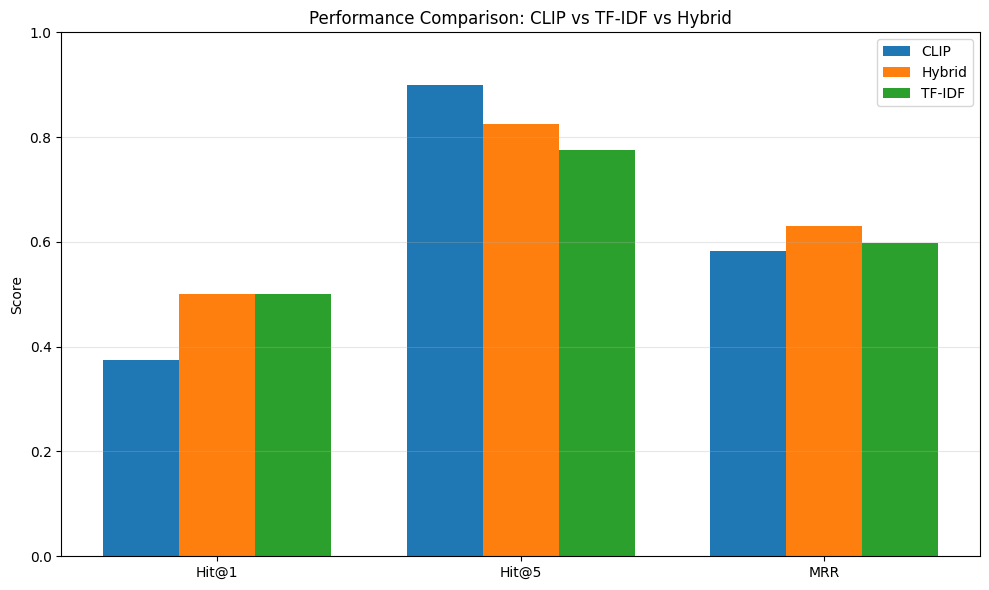

Graph saved successfully!


In [45]:
import matplotlib.pyplot as plt
import numpy as np
import os

metrics = ["Hit@1", "Hit@5", "MRR"]

methods = final_comparison_40["Method"].tolist()

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(10, 6))

for i, method in enumerate(methods):
    values = final_comparison_40[
        final_comparison_40["Method"] == method
    ][metrics].values[0]

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=method
    )

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Performance Comparison: CLIP vs TF-IDF vs Hybrid")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(project_root, "results/figures/method_comparison.png"),
    dpi=300
)

plt.show()

print("Graph saved successfully!")

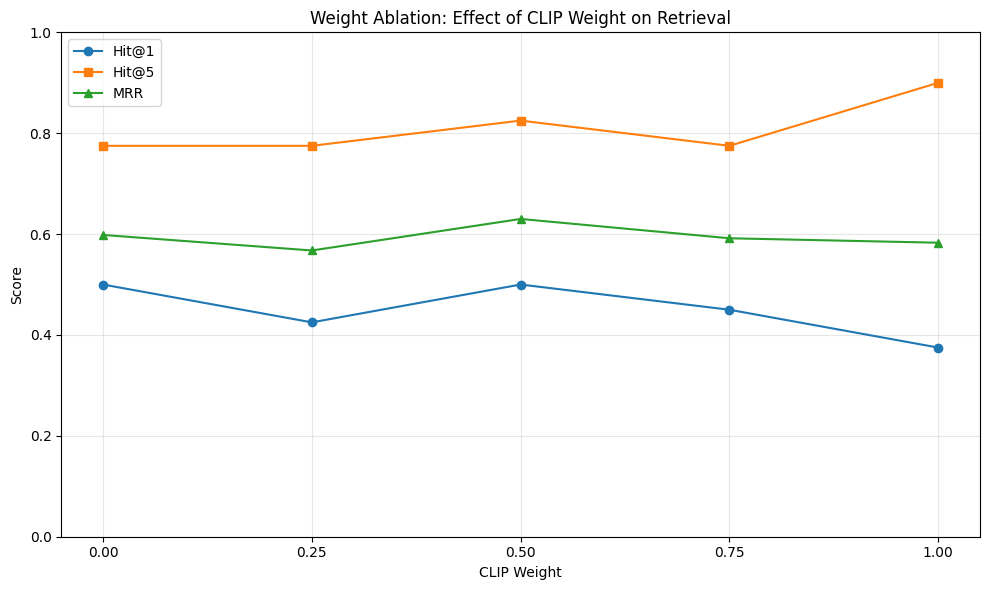

Weight ablation graph saved successfully!


In [46]:
plt.figure(figsize=(10, 6))

plt.plot(
    ablation_summary_40["CLIP Weight"],
    ablation_summary_40["Hit@1"],
    marker="o",
    label="Hit@1"
)

plt.plot(
    ablation_summary_40["CLIP Weight"],
    ablation_summary_40["Hit@5"],
    marker="s",
    label="Hit@5"
)

plt.plot(
    ablation_summary_40["CLIP Weight"],
    ablation_summary_40["MRR"],
    marker="^",
    label="MRR"
)

plt.xlabel("CLIP Weight")
plt.ylabel("Score")
plt.title("Weight Ablation: Effect of CLIP Weight on Retrieval")
plt.xticks([0, 0.25, 0.50, 0.75, 1.0])
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        project_root,
        "results/figures/weight_ablation.png"
    ),
    dpi=300
)

plt.show()

print("Weight ablation graph saved successfully!")

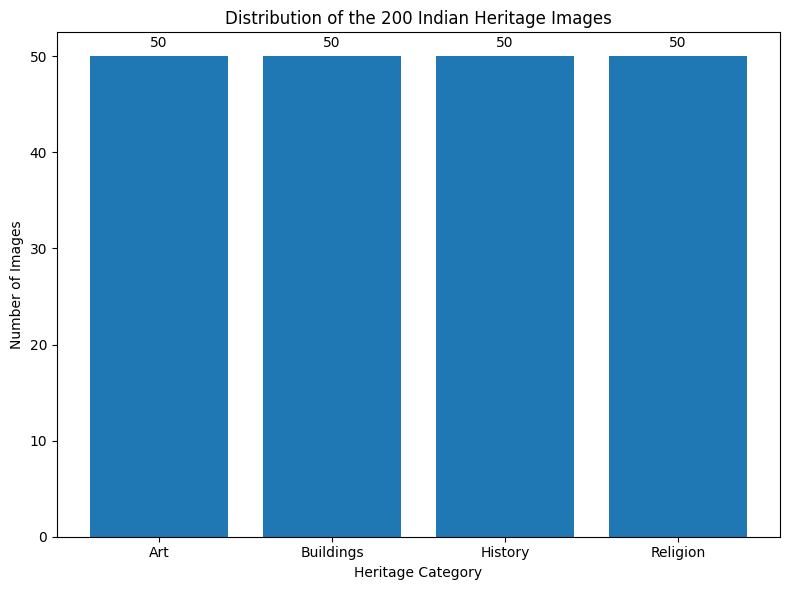

Dataset distribution graph saved!


In [47]:
domain_counts = subset_manifest["domain"].value_counts()

plt.figure(figsize=(8, 6))

plt.bar(domain_counts.index, domain_counts.values)

plt.xlabel("Heritage Category")
plt.ylabel("Number of Images")
plt.title("Distribution of the 200 Indian Heritage Images")

for i, value in enumerate(domain_counts.values):
    plt.text(i, value + 1, str(value), ha="center")

plt.tight_layout()

plt.savefig(
    os.path.join(
        project_root,
        "results/figures/dataset_distribution.png"
    ),
    dpi=300
)

plt.show()

print("Dataset distribution graph saved!")

In [48]:
additional_queries = {
    # ART — 10 additional queries
    "Traditional Indian percussion instruments": "Art",
    "Ancient Indian bronze sculptures": "Art",
    "Indian traditional masks and crafts": "Art",
    "Decorative Indian cultural objects": "Art",
    "Traditional Indian paintings and murals": "Art",
    "Indian folk musical instruments": "Art",
    "Ancient Indian artistic carvings": "Art",
    "Traditional Indian craft objects": "Art",
    "Indian heritage sculptures": "Art",
    "Cultural art of northeastern India": "Art",

    # BUILDINGS — 10 additional queries
    "Ancient Indian cave architecture": "Buildings",
    "Historic Indian stone architecture": "Buildings",
    "Traditional Indian monuments and structures": "Buildings",
    "Ancient Indian architectural remains": "Buildings",
    "Historic Indian gateways and entrances": "Buildings",
    "Indian heritage buildings and landmarks": "Buildings",
    "Ancient Indian rock-cut architecture": "Buildings",
    "Historical Indian forts": "Buildings",
    "Traditional Indian architectural monuments": "Buildings",
    "Old Indian palace architecture": "Buildings",

    # HISTORY — 10 additional queries
    "Ancient Indian archaeological artefacts": "History",
    "Historical Indian stone inscriptions": "History",
    "Indian ancient historical relics": "History",
    "Archaeological remains of ancient India": "History",
    "Ancient Indian heritage objects": "History",
    "Historical sculptures from India": "History",
    "Indian historical excavation sites": "History",
    "Ancient Indian cultural remains": "History",
    "Historical landmarks of Karnataka": "History",
    "Indian ancient inscriptions and records": "History",

    # RELIGION — 10 additional queries
    "Ancient Buddhist temples in India": "Religion",
    "Hindu temple sculptures": "Religion",
    "Jain religious monuments in India": "Religion",
    "Buddhist heritage sites": "Religion",
    "Ancient Indian sacred shrines": "Religion",
    "Hindu religious statues": "Religion",
    "Jain architectural heritage": "Religion",
    "Buddhist stone sculptures": "Religion",
    "Indian sacred temple architecture": "Religion",
    "Ancient religious carvings in India": "Religion"
}

evaluation_queries_80 = {
    **evaluation_queries_40,
    **additional_queries
}

print("Total queries:", len(evaluation_queries_80))
print("\nQueries per category:")
print(pd.Series(evaluation_queries_80).value_counts())

Total queries: 80

Queries per category:
Art          20
Buildings    20
History      20
Religion     20
Name: count, dtype: int64


In [49]:
evaluation_results_80 = []

methods = {
    "CLIP": search_images,
    "TF-IDF": tfidf_search,
    "Hybrid": hybrid_search
}

for method_name, search_function in methods.items():

    print(f"Evaluating {method_name}...")

    for query, relevant_domain in evaluation_queries_80.items():

        if method_name == "Hybrid":
            results = search_function(query, top_k=5, weight=0.50)
        else:
            results = search_function(query, top_k=5)

        domains = results["domain"].tolist()

        relevant_ranks = [
            rank for rank, domain in enumerate(domains, start=1)
            if domain == relevant_domain
        ]

        evaluation_results_80.append({
            "Method": method_name,
            "Query": query,
            "Expected Domain": relevant_domain,
            "Hit@1": int(
                len(domains) > 0 and domains[0] == relevant_domain
            ),
            "Hit@5": int(len(relevant_ranks) > 0),
            "MRR": 1 / relevant_ranks[0] if relevant_ranks else 0
        })

evaluation_df_80 = pd.DataFrame(evaluation_results_80)

print("\n80-QUERY EVALUATION COMPLETED!")
print("Total evaluation records:", len(evaluation_df_80))

display(evaluation_df_80.head(10))

Evaluating CLIP...
Evaluating TF-IDF...
Evaluating Hybrid...

80-QUERY EVALUATION COMPLETED!
Total evaluation records: 240


,Method,Query,Expected Domain,Hit@1,Hit@5,MRR
0,CLIP,Traditional Indian painting,Art,0,1,0.50
1,CLIP,Indian sculpture and artwork,Art,1,1,1.00
2,CLIP,Ancient Indian artistic designs,Art,0,1,0.50
3,CLIP,Traditional Indian handicrafts,Art,0,1,0.50
4,CLIP,Indian musical instruments,Art,1,1,1.00
5,CLIP,Traditional Indian folk art,Art,1,1,1.00
6,CLIP,Indian cultural artefacts,Art,1,1,1.00
7,CLIP,Ancient Indian statues,Art,0,1,0.25
8,CLIP,Traditional Indian decorative art,Art,1,1,1.00
9,CLIP,Indian artistic heritage,Art,0,1,0.50


In [50]:
final_comparison_80 = (
    evaluation_df_80
    .groupby("Method")[["Hit@1", "Hit@5", "MRR"]]
    .mean()
    .reset_index()
    .round(4)
)

print("FINAL PERFORMANCE — 80 QUERIES")
display(final_comparison_80)

FINAL PERFORMANCE — 80 QUERIES


,Method,Hit@1,Hit@5,MRR
0,CLIP,0.4250,0.8875,0.6069
1,Hybrid,0.5125,0.8000,0.6225
2,TF-IDF,0.4750,0.7875,0.5823


In [51]:
evaluation_df_80.to_csv(
    os.path.join(project_root, "results/tables/80_query_level_results.csv"),
    index=False
)

final_comparison_80.to_csv(
    os.path.join(project_root, "results/tables/80_query_comparison.csv"),
    index=False
)

print("80-query evaluation results saved successfully!")

80-query evaluation results saved successfully!


In [52]:
weights = [0, 0.25, 0.50, 0.75, 1.0]

ablation_results_80 = []

for weight in weights:

    print(f"Testing CLIP weight: {weight}")

    for query, relevant_domain in evaluation_queries_80.items():

        results = hybrid_search(
            query,
            top_k=5,
            weight=weight
        )

        domains = results["domain"].tolist()

        relevant_ranks = [
            rank for rank, domain in enumerate(domains, start=1)
            if domain == relevant_domain
        ]

        ablation_results_80.append({
            "CLIP Weight": weight,
            "Query": query,
            "Expected Domain": relevant_domain,
            "Hit@1": int(
                len(domains) > 0 and domains[0] == relevant_domain
            ),
            "Hit@5": int(len(relevant_ranks) > 0),
            "MRR": 1 / relevant_ranks[0] if relevant_ranks else 0
        })

ablation_df_80 = pd.DataFrame(ablation_results_80)

ablation_summary_80 = (
    ablation_df_80
    .groupby("CLIP Weight")[["Hit@1", "Hit@5", "MRR"]]
    .mean()
    .reset_index()
    .round(4)
)

print("\n80-QUERY WEIGHT ABLATION COMPLETED!")
display(ablation_summary_80)

Testing CLIP weight: 0
Testing CLIP weight: 0.25
Testing CLIP weight: 0.5
Testing CLIP weight: 0.75
Testing CLIP weight: 1.0

80-QUERY WEIGHT ABLATION COMPLETED!


,CLIP Weight,Hit@1,Hit@5,MRR
0,0.00,0.4750,0.7875,0.5823
1,0.25,0.4500,0.7750,0.5796
2,0.50,0.5125,0.8000,0.6225
3,0.75,0.4375,0.7625,0.5685
4,1.00,0.4250,0.8875,0.6069


In [53]:
import os

tables_dir = os.path.join(project_root, "results", "tables")

ablation_df_80.to_csv(
    os.path.join(tables_dir, "80_query_ablation_level_results.csv"),
    index=False
)

ablation_summary_80.to_csv(
    os.path.join(tables_dir, "80_query_weight_ablation.csv"),
    index=False
)

print("80-query ablation results saved successfully!")

80-query ablation results saved successfully!


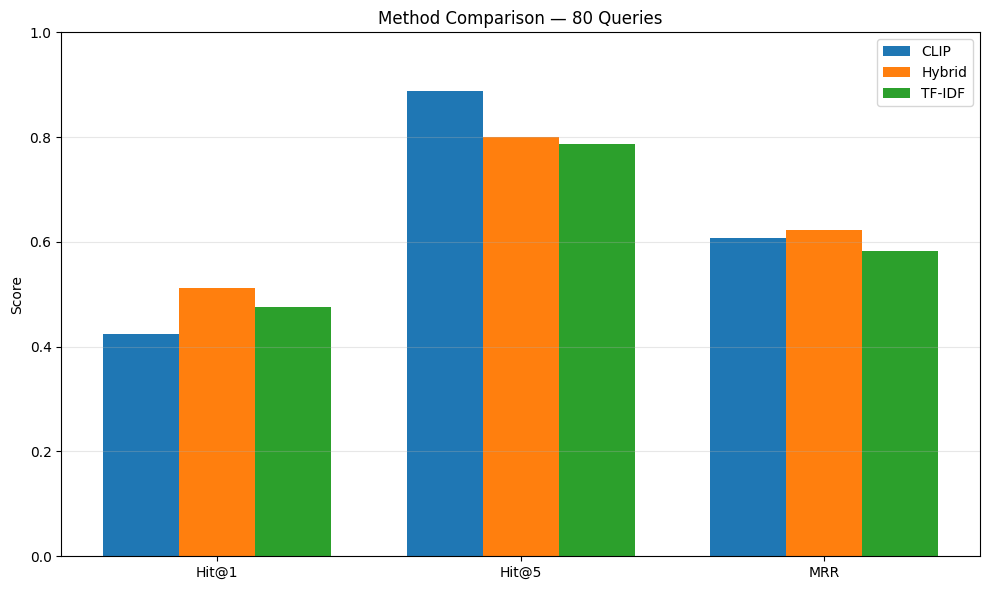

Updated 80-query comparison graph saved!


In [54]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Use final 80-query results
df = final_comparison_80.copy()

metrics = ["Hit@1", "Hit@5", "MRR"]
methods = df["Method"].tolist()

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(10, 6))

for i, method in enumerate(methods):
    values = df[df["Method"] == method][metrics].values[0]
    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=method
    )

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Method Comparison — 80 Queries")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save updated graph
figures_dir = os.path.join(project_root, "results", "figures")
os.makedirs(figures_dir, exist_ok=True)

plt.savefig(
    os.path.join(figures_dir, "method_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Updated 80-query comparison graph saved!")

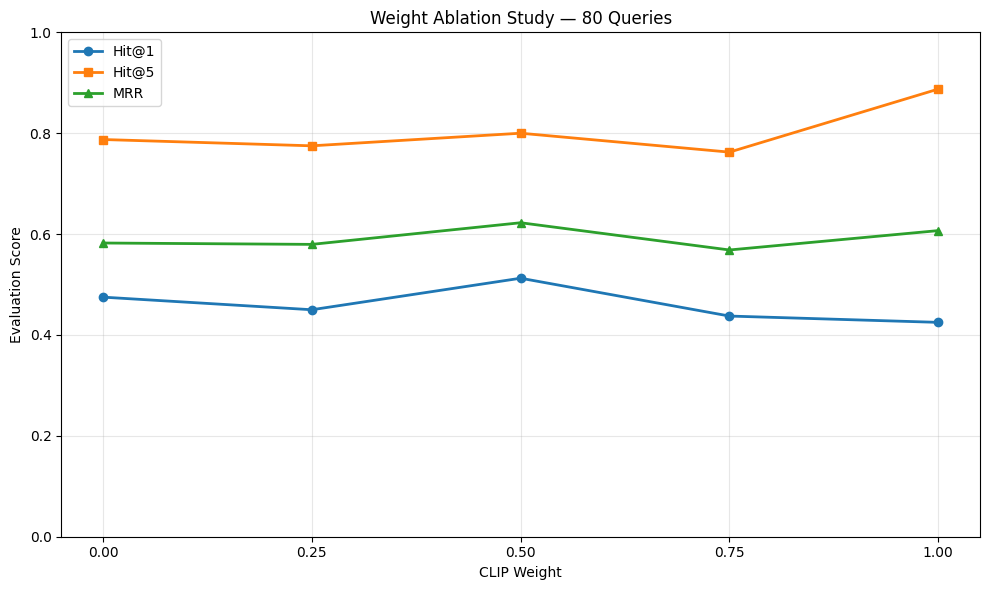

Final 80-query weight ablation graph saved successfully!


In [55]:
import matplotlib.pyplot as plt
import os

# Final 80-query ablation results
df = ablation_summary_80.copy()

plt.figure(figsize=(10, 6))

plt.plot(df["CLIP Weight"], df["Hit@1"],
         marker="o", linewidth=2, label="Hit@1")

plt.plot(df["CLIP Weight"], df["Hit@5"],
         marker="s", linewidth=2, label="Hit@5")

plt.plot(df["CLIP Weight"], df["MRR"],
         marker="^", linewidth=2, label="MRR")

plt.xlabel("CLIP Weight")
plt.ylabel("Evaluation Score")
plt.title("Weight Ablation Study — 80 Queries")

plt.xticks([0, 0.25, 0.50, 0.75, 1.0])
plt.ylim(0, 1)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save graph
figures_dir = os.path.join(project_root, "results", "figures")
os.makedirs(figures_dir, exist_ok=True)

plt.savefig(
    os.path.join(figures_dir, "weight_ablation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final 80-query weight ablation graph saved successfully!")

In [56]:
print("Evaluation dataframe columns:")
print(evaluation_df_80.columns.tolist())

print("\nFirst 5 evaluation records:")
display(evaluation_df_80.head())

Evaluation dataframe columns:
['Method', 'Query', 'Expected Domain', 'Hit@1', 'Hit@5', 'MRR']

First 5 evaluation records:


,Method,Query,Expected Domain,Hit@1,Hit@5,MRR
0,CLIP,Traditional Indian painting,Art,0,1,0.5
1,CLIP,Indian sculpture and artwork,Art,1,1,1.0
2,CLIP,Ancient Indian artistic designs,Art,0,1,0.5
3,CLIP,Traditional Indian handicrafts,Art,0,1,0.5
4,CLIP,Indian musical instruments,Art,1,1,1.0


In [57]:
# Identify failed queries
failure_cases = evaluation_df_80[
    evaluation_df_80["Hit@5"] == 0
].copy()

# Display failures grouped by method
print("TOTAL FAILURE CASES:", len(failure_cases))

print("\nFAILURE COUNT BY METHOD:")
display(
    failure_cases.groupby("Method").size().reset_index(
        name="Number of Failures"
    )
)

print("\nDETAILED FAILURE CASES:")
display(
    failure_cases[
        ["Method", "Query", "Expected Domain", "Hit@1", "Hit@5", "MRR"]
    ].sort_values(["Method", "Expected Domain"])
)

TOTAL FAILURE CASES: 42

FAILURE COUNT BY METHOD:


,Method,Number of Failures
0,CLIP,9
1,Hybrid,16
2,TF-IDF,17



DETAILED FAILURE CASES:


,Method,Query,Expected Domain,Hit@1,Hit@5,MRR
12,CLIP,Ancient Indian buildings,Buildings,0,0,0.0
15,CLIP,Ancient Indian stone structures,Buildings,0,0,0.0
18,CLIP,Traditional Indian houses,Buildings,0,0,0.0
19,CLIP,Ancient Indian architectural sites,Buildings,0,0,0.0
50,CLIP,Ancient Indian cave architecture,Buildings,0,0,0.0
53,CLIP,Ancient Indian architectural remains,Buildings,0,0,0.0
56,CLIP,Ancient Indian rock-cut architecture,Buildings,0,0,0.0
57,CLIP,Historical Indian forts,Buildings,0,0,0.0
77,CLIP,Buddhist stone sculptures,Religion,0,0,0.0
167,Hybrid,Ancient Indian statues,Art,0,0,0.0


In [58]:
failure_cases.to_csv(
    os.path.join(
        project_root,
        "results",
        "tables",
        "failure_analysis_80_queries.csv"
    ),
    index=False
)

print("Failure analysis saved successfully!")

Failure analysis saved successfully!


In [59]:
# Failure count by method and domain
failure_summary = (
    failure_cases
    .groupby(["Method", "Expected Domain"])
    .size()
    .reset_index(name="Failures")
)

print("FAILURES BY METHOD AND DOMAIN:")
display(
    failure_summary.pivot(
        index="Expected Domain",
        columns="Method",
        values="Failures"
    ).fillna(0).astype(int)
)

# Save summary
failure_summary.to_csv(
    os.path.join(
        project_root,
        "results",
        "tables",
        "failure_summary_by_domain.csv"
    ),
    index=False
)

# Save detailed failure cases
failure_cases.to_csv(
    os.path.join(
        project_root,
        "results",
        "tables",
        "failure_analysis_80_queries.csv"
    ),
    index=False
)

print("Failure analysis files saved successfully!")

FAILURES BY METHOD AND DOMAIN:


Method,CLIP,Hybrid,TF-IDF
Expected Domain,,,
Art,0,4,0
Buildings,8,10,14
Religion,1,2,3


Failure analysis files saved successfully!


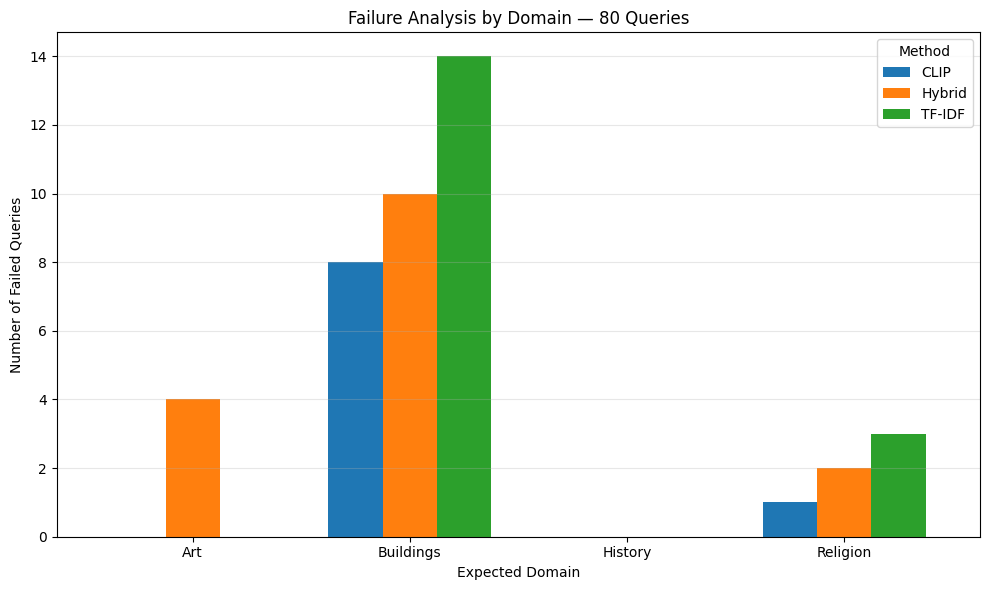

Failure analysis graph saved successfully!


In [60]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Prepare failure data
plot_df = failure_summary.pivot(
    index="Expected Domain",
    columns="Method",
    values="Failures"
).fillna(0)

# Include History even though it has zero failures
plot_df = plot_df.reindex(
    ["Art", "Buildings", "History", "Religion"],
    fill_value=0
)

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Failure Analysis by Domain — 80 Queries")
plt.xlabel("Expected Domain")
plt.ylabel("Number of Failed Queries")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Method")
plt.tight_layout()

# Save figure
figures_dir = os.path.join(project_root, "results", "figures")

plt.savefig(
    os.path.join(figures_dir, "failure_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Failure analysis graph saved successfully!")

In [61]:
import os
import subprocess

project_root = "/content/drive/MyDrive/UCS532-CV-PROJECT"

os.chdir(project_root)

print("PROJECT DIRECTORY:")
print(os.getcwd())

print("\nGITHUB STATUS:")
!git status --short

print("\nTRACKED FILES:")
!git ls-files

print("\nPROJECT FOLDERS:")
for root, dirs, files in os.walk(project_root):
    dirs[:] = [d for d in dirs if d != ".git"]
    level = root.replace(project_root, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")


PROJECT DIRECTORY:
/content/drive/MyDrive/UCS532-CV-PROJECT

GITHUB STATUS:
Refresh index: 100% (11/11), done.
?? data/images/0.jpg
?? data/images/1.jpg
?? data/images/10.jpg
?? data/images/100.jpg
?? data/images/101.jpg
?? data/images/102.jpg
?? data/images/103.jpg
?? data/images/104.jpg
?? data/images/105.jpg
?? data/images/106.jpg
?? data/images/107.jpg
?? data/images/108.jpg
?? data/images/109.jpg
?? data/images/11.jpg
?? data/images/110.jpg
?? data/images/111.jpg
?? data/images/112.jpg
?? data/images/113.jpg
?? data/images/114.jpg
?? data/images/115.jpg
?? data/images/116.jpg
?? data/images/117.jpg
?? data/images/118.jpg
?? data/images/119.jpg
?? data/images/12.jpg
?? data/images/120.jpg
?? data/images/121.jpg
?? data/images/122.jpg
?? data/images/123.jpg
?? data/images/124.jpg
?? data/images/125.jpg
?? data/images/126.jpg
?? data/images/127.jpg
?? data/images/128.jpg
?? data/images/129.jpg
?? data/images/13.jpg
?? data/images/130.jpg
?? data/images/131.jpg
?? data/images/132.jpg


In [62]:
import os

os.chdir(project_root)

print("========== README.md ==========")

with open("README.md", "r") as f:
    print(f.read())

print("\n========== .gitignore ==========")

with open(".gitignore", "r") as f:
    print(f.read())

========== README.md ==========
# UCS532-CV-PROJECT
CV-Open Challenge


========== .gitignore ==========
# Byte-compiled / optimized / DLL files
__pycache__/
*.py[codz]
*$py.class

# C extensions
*.so

# Distribution / packaging
.Python
build/
develop-eggs/
dist/
downloads/
eggs/
.eggs/
lib/
lib64/
parts/
sdist/
var/
wheels/
share/python-wheels/
*.egg-info/
.installed.cfg
*.egg
MANIFEST

# PyInstaller
#   Usually these files are written by a python script from a template
#   before PyInstaller builds the exe, so as to inject date/other infos into it.
*.manifest
*.spec

# Installer logs
pip-log.txt
pip-delete-this-directory.txt

# Unit test / coverage reports
htmlcov/
.tox/
.nox/
.coverage
.coverage.*
.cache
nosetests.xml
coverage.xml
*.cover
*.py.cover
*.lcov
.hypothesis/
.pytest_cache/
cover/

# Translations
*.mo
*.pot

# Django stuff:
*.log
local_settings.py
db.sqlite3
db.sqlite3-journal

# Flask stuff:
instance/
.webassets-cache

# Scrapy stuff:
.scrapy

# Sphinx documentation
docs/

In [63]:
import os

os.chdir(project_root)

project_ignores = """

# Project-specific exclusions

# Dataset images and metadata
data/images/
data/dataset_manifest.csv
data/selected_200.csv
data/subset_manifest.csv

# Model embeddings and checkpoints
results/embeddings/
*.pt
*.pth
*.ckpt

# Local credentials and environment files
.env
.env.*
"""

with open(".gitignore", "a") as f:
    f.write(project_ignores)

print("Project-specific .gitignore rules added!")

Project-specific .gitignore rules added!


In [64]:
os.chdir(project_root)

!git rm --cached data/dataset_manifest.csv

print("\nUpdated Git status:")
!git status --short

rm 'data/dataset_manifest.csv'

Updated Git status:
 M .gitignore
D  data/dataset_manifest.csv
?? results/figures/dataset_distribution.png
?? results/figures/failure_analysis.png
?? results/figures/method_comparison.png
?? results/figures/weight_ablation.png
?? results/tables/16_query_comparison.csv
?? results/tables/40_query_comparison.csv
?? results/tables/40_query_level_results.csv
?? results/tables/80_query_ablation_level_results.csv
?? results/tables/80_query_comparison.csv
?? results/tables/80_query_level_results.csv
?? results/tables/80_query_weight_ablation.csv
?? results/tables/domain_evaluation.csv
?? results/tables/failure_analysis_80_queries.csv
?? results/tables/failure_summary_by_domain.csv
?? results/tables/final_comparison.csv
?? results/tables/query_level_results.csv
?? results/tables/weight_ablation.csv
?? results/tables/weight_ablation_16_queries.csv
?? results/tables/weight_ablation_40_queries.csv
?? results/tables/weight_ablation_40_query_level.csv


In [65]:
import os

os.chdir("/content/drive/MyDrive/UCS532-CV-PROJECT")

print("SOURCE FILES:")
for root, dirs, files in os.walk("src"):
    for file in files:
        print(os.path.join(root, file))

print("\nCONTENT OF src/load_data.py:")
with open("src/load_data.py", "r") as f:
    print(f.read())

SOURCE FILES:
src/.gitkeep
src/load_data.py

CONTENT OF src/load_data.py:
import random
import numpy as np
import pandas as pd
from datasets import load_dataset

SEED = 42

def load_bodhisetu():
    random.seed(SEED)
    np.random.seed(SEED)

    print("Loading Bodhisetu enriched dataset...")

    dataset = load_dataset(
        "51Hypers/Bodhisetu",
        "enriched",
        split="train"
    )

    df = dataset.to_pandas()

    images_df = df[
        df["media_type"].astype(str).str.upper() == "IMAGE"
    ].copy()

    print("Total records:", len(df))
    print("Total images:", len(images_df))

    return df, images_df

if __name__ == "__main__":
    df, images_df = load_bodhisetu()
    images_df.to_csv("data/dataset_manifest.csv", index=False)
    print("Manifest saved!")



In [66]:
import os

os.chdir("/content/drive/MyDrive/UCS532-CV-PROJECT")

print("PROJECT FILES:\n")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".git", "images", "__pycache__"]]
    for file in files:
        print(os.path.join(root, file))

PROJECT FILES:

./.gitignore
./README.md
./configs/.gitkeep
./data/dataset_manifest.csv
./data/selected_200.csv
./data/subset_manifest.csv
./report/.gitkeep
./results/figures/.gitkeep
./results/figures/method_comparison.png
./results/figures/weight_ablation.png
./results/figures/dataset_distribution.png
./results/figures/failure_analysis.png
./results/logs/.gitkeep
./results/tables/.gitkeep
./results/tables/domain_evaluation.csv
./results/tables/final_comparison.csv
./results/tables/weight_ablation.csv
./results/tables/query_level_results.csv
./results/tables/16_query_comparison.csv
./results/tables/weight_ablation_16_queries.csv
./results/tables/40_query_level_results.csv
./results/tables/40_query_comparison.csv
./results/tables/weight_ablation_40_queries.csv
./results/tables/weight_ablation_40_query_level.csv
./results/tables/80_query_level_results.csv
./results/tables/80_query_comparison.csv
./results/tables/80_query_ablation_level_results.csv
./results/tables/80_query_weight_ablati